# Análisis y clustering de rostros (Jerárquico, K-Means, DBSCAN, HDBSCAN y OPTICS)
**Flujo:** `fotos/` → detección y recorte de rostros → `personas/` → extracción de características → clustering jerárquico → gráficas.

Carpetas esperadas en tu Drive (se crean solas si no existen):
- `MyDrive/ANALISIS_ROSTROS/fotos`    → aquí subes las fotos originales
- `MyDrive/ANALISIS_ROSTROS/personas` → aquí se guardan los rostros recortados
- `MyDrive/ANALISIS_ROSTROS/resultados` → gráficas y CSV

In [1]:
# ---------------------------------------------------------
# 0) Configuración
# ---------------------------------------------------------
import os, glob
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             calinski_harabasz_score, davies_bouldin_score)
from scipy.cluster.hierarchy import dendrogram, linkage
from skimage.feature import local_binary_pattern, hog
from google.colab import drive

drive.mount('/content/drive')

BASE      = "/content/drive/MyDrive/ANALISIS_ROSTROS"
FOTOS     = os.path.join(BASE, "fotos")
PERSONAS  = os.path.join(BASE, "personas")
RESULTADOS = os.path.join(BASE, "resultados")
for c in (FOTOS, PERSONAS, RESULTADOS):
    os.makedirs(c, exist_ok=True)

# ---- Parámetros que puedes ajustar ----
LADO_MIN_ANALISIS  = 24   # al analizar, ignora recortes con lado menor a esto (px)
# (Los parámetros de detección de rostros están al inicio de la celda 1.)
LIMPIAR_PERSONAS = False  # True = borra los recortes anteriores antes de volver a recortar
K_MAX            = 10     # máximo de clusters a evaluar
K_ELEGIDO        = 3   # None = automático (mejor silhouette). O pon un número, ej. 4

# Peso de cada grupo de características en el clustering
PESOS = {"color": 1.0, "luz": 1.0, "textura": 1.0,
         "forma": 1.0, "lentes": 1.5, "simetria": 0.5}

def guardar(nombre):
    plt.savefig(os.path.join(RESULTADOS, nombre), dpi=150, bbox_inches="tight")

print("Fotos en:", FOTOS)
print("Rostros en:", PERSONAS)

Mounted at /content/drive
Fotos en: /content/drive/MyDrive/ANALISIS_ROSTROS/fotos
Rostros en: /content/drive/MyDrive/ANALISIS_ROSTROS/personas


## 1) Detectar y recortar rostros (fotos grupales)
Se usa **MTCNN** (detector pensado para caras pequeñas) aplicado por **mosaicos y a varias escalas**, de modo
que las personas del fondo también se detecten. Cada rostro se guarda como recorte **cuadrado de 128×128**
en `personas/`. YuNet queda como detector opcional (`DETECTOR = "ambos"`).

Por cada foto se imprime un diagnóstico: detecciones crudas → tras filtros de tamaño/forma → tras quitar duplicados.
Si faltan caras: baja `PROB_MIN` (0.90 → 0.80) o usa `DETECTOR = "ambos"`.
Después corre la celda de **revisión** para descartar falsos positivos.

Detectores activos: ['_det_mtcnn'] | dispositivo: cpu
5 fotos encontradas.

  photo_5035492685619334303_y.jpg: 19 rostros  (detecciones crudas: 98 → tras filtros de tamaño/forma: 94 → tras quitar duplicados: 19)
  photo_5096136369708403896_x.jpg: 18 rostros  (detecciones crudas: 106 → tras filtros de tamaño/forma: 106 → tras quitar duplicados: 18)
  photo_5096136369708403897_w.jpg: 34 rostros  (detecciones crudas: 198 → tras filtros de tamaño/forma: 198 → tras quitar duplicados: 34)
  photo_5096136369708403898_w.jpg: 64 rostros  (detecciones crudas: 389 → tras filtros de tamaño/forma: 389 → tras quitar duplicados: 64)
  photo_5096136369708403899_w.jpg: 51 rostros  (detecciones crudas: 274 → tras filtros de tamaño/forma: 274 → tras quitar duplicados: 51)

Total de rostros guardados: 186


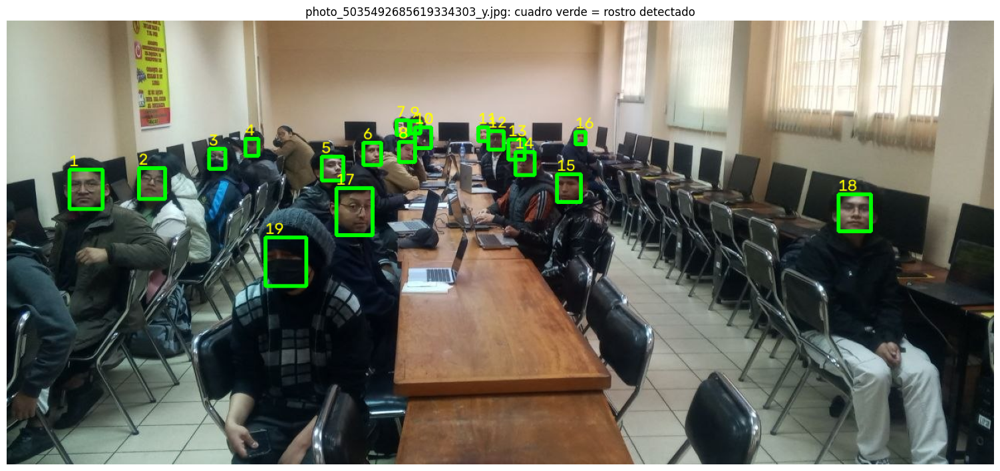

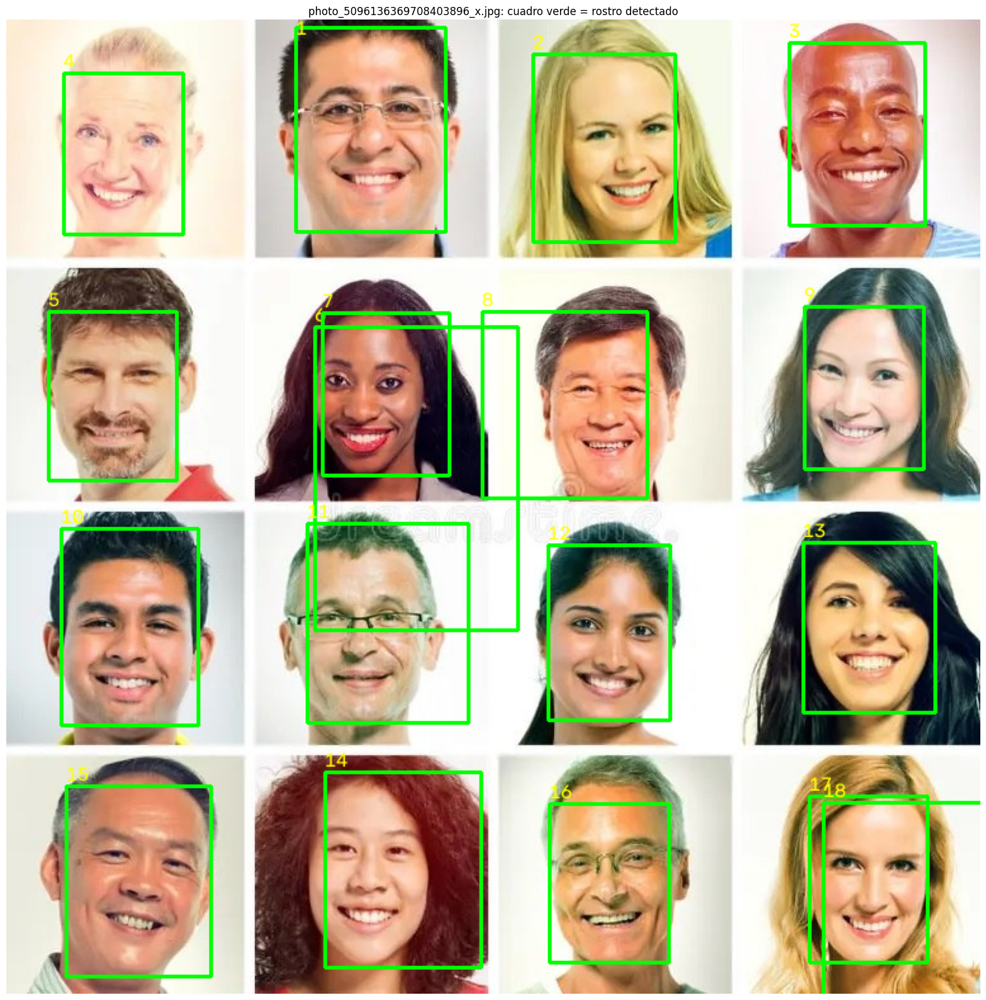

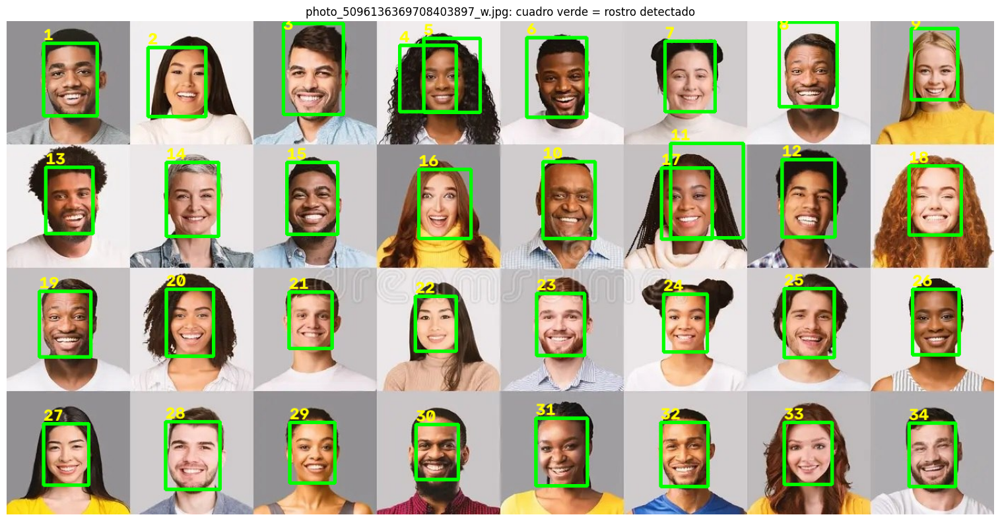

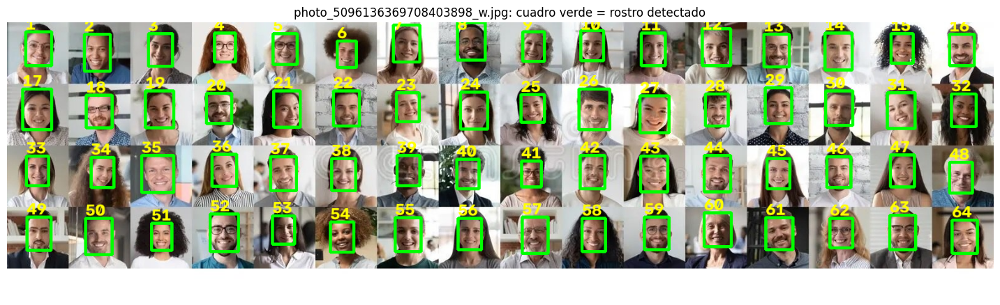

In [2]:
import subprocess, sys, urllib.request
from PIL import Image

try:
    import torch
    from facenet_pytorch import MTCNN
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "facenet-pytorch", "--no-deps"], check=True)
    import torch
    from facenet_pytorch import MTCNN

# ---------------- Parámetros (ajústalos aquí, no hace falta tocar la primera celda) ----------------
DETECTOR       = "mtcnn"          # "mtcnn", "yunet" o "ambos" (ambos = más cobertura, más falsos positivos)
ESCALAS        = (1.0, 1.5, 2.0)  # tamaños a los que se busca; >1 ayuda con caras lejanas
TILE, SOLAPE   = 640, 0.3         # mosaico (px) y solape entre mosaicos
PROB_MIN       = 0.90             # confianza mínima de MTCNN (bájala a 0.80 si aún faltan caras)
SCORE_MIN      = 0.60             # confianza mínima de YuNet (solo si DETECTOR != "mtcnn")
IOU_NMS        = 0.40             # cajas que se solapan más que esto se consideran la misma cara
LADO_MIN_DET   = 12               # lado mínimo de un rostro en la foto ORIGINAL (px)
ASPECTO        = (0.5, 1.6)       # ancho/alto permitido: descarta cajas deformes (falsos positivos)
MARGEN_RECORTE = 0.25             # margen extra alrededor del rostro
TAM_SALIDA     = 128              # recortes cuadrados de este tamaño (None = tamaño original)
MAX_LADO_ESCALADO = 4000          # no agrandar imágenes por encima de este lado (protege la RAM)

# ---------------- Detectores ----------------
dispositivo = "cuda" if torch.cuda.is_available() else "cpu"
mtcnn = MTCNN(keep_all=True, min_face_size=20, thresholds=[0.6, 0.7, 0.7], device=dispositivo)

yunet = None
if DETECTOR in ("yunet", "ambos"):
    YUNET_URL = "https://github.com/opencv/opencv_zoo/raw/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx"
    YUNET_PATH = os.path.join(BASE, "face_detection_yunet_2023mar.onnx")
    try:
        if not os.path.exists(YUNET_PATH) or os.path.getsize(YUNET_PATH) < 100_000:
            urllib.request.urlretrieve(YUNET_URL, YUNET_PATH)
        yunet = cv2.FaceDetectorYN.create(YUNET_PATH, "", (320, 320), SCORE_MIN, 0.3, 5000)
    except Exception as e:
        print("⚠ No pude cargar YuNet, uso solo MTCNN:", e)

def _det_mtcnn(crop_rgb):
    """Devuelve [(x1, y1, x2, y2, prob)] en coordenadas del mosaico."""
    boxes, probs = mtcnn.detect(Image.fromarray(crop_rgb))
    if boxes is None:
        return []
    return [(*b, float(p)) for b, p in zip(boxes, probs) if p is not None and p >= PROB_MIN]

def _det_yunet(crop_rgb):
    t = np.ascontiguousarray(cv2.cvtColor(crop_rgb, cv2.COLOR_RGB2BGR))
    yunet.setInputSize((t.shape[1], t.shape[0]))
    _, caras = yunet.detect(t)
    if caras is None:
        return []
    return [(c[0], c[1], c[0] + c[2], c[1] + c[3], float(c[-1])) for c in caras]

DETECTORES = []
if DETECTOR in ("mtcnn", "ambos"):
    DETECTORES.append(_det_mtcnn)
if yunet is not None:
    DETECTORES.append(_det_yunet)
if not DETECTORES:
    DETECTORES.append(_det_mtcnn)
print("Detectores activos:", [d.__name__ for d in DETECTORES], "| dispositivo:", dispositivo)

# ---------------- Mosaicos, NMS, detección ----------------
def _inicios(L, t, paso):
    if L <= t:
        return [0]
    s = list(range(0, L - t + 1, paso))
    if s[-1] + t < L:
        s.append(L - t)
    return s

def _mosaicos(im):
    h, w = im.shape[:2]
    th, tw = min(TILE, h), min(TILE, w)
    for y in _inicios(h, th, max(int(th * (1 - SOLAPE)), 1)):
        for x in _inicios(w, tw, max(int(tw * (1 - SOLAPE)), 1)):
            yield x, y, np.ascontiguousarray(im[y:y + th, x:x + tw])

def _nms(cajas, scores, iou_max):
    """cajas = [x, y, w, h]. Devuelve los índices que se conservan."""
    if not cajas:
        return []
    b = np.array(cajas, float)
    x1, y1 = b[:, 0], b[:, 1]
    x2, y2 = x1 + b[:, 2], y1 + b[:, 3]
    area = b[:, 2] * b[:, 3]
    orden, keep = np.argsort(scores)[::-1], []
    while orden.size:
        i, r = orden[0], orden[1:]
        keep.append(int(i))
        iw = np.clip(np.minimum(x2[i], x2[r]) - np.maximum(x1[i], x1[r]), 0, None)
        ih = np.clip(np.minimum(y2[i], y2[r]) - np.maximum(y1[i], y1[r]), 0, None)
        iou = iw * ih / (area[i] + area[r] - iw * ih + 1e-9)
        orden = r[iou <= iou_max]
    return keep

def detectar_rostros(img_rgb):
    """Devuelve ([(x1, y1, x2, y2, score)], estadisticas) en coordenadas de la foto original."""
    H, W = img_rgb.shape[:2]
    cajas, scores = [], []
    crudas = 0
    for s in [e for e in ESCALAS if e == 1 or max(H, W) * e <= MAX_LADO_ESCALADO]:
        im = img_rgb if s == 1 else cv2.resize(img_rgb, None, fx=s, fy=s, interpolation=cv2.INTER_CUBIC)
        for x0, y0, crop in _mosaicos(im):
            for det in DETECTORES:
                for (x1, y1, x2, y2, p) in det(crop):
                    crudas += 1
                    bx1, by1, bx2, by2 = (x1 + x0) / s, (y1 + y0) / s, (x2 + x0) / s, (y2 + y0) / s
                    bw, bh = bx2 - bx1, by2 - by1
                    if bw <= 0 or bh <= 0 or min(bw, bh) < LADO_MIN_DET:
                        continue
                    if not (ASPECTO[0] < bw / bh < ASPECTO[1]):
                        continue
                    cajas.append([bx1, by1, bw, bh]); scores.append(p)
    keep = _nms(cajas, scores, IOU_NMS)
    res = [(cajas[i][0], cajas[i][1], cajas[i][0] + cajas[i][2], cajas[i][1] + cajas[i][3], scores[i]) for i in keep]
    return res, {"crudas": crudas, "tras_filtros": len(cajas), "finales": len(res)}

def recorte_cuadrado(img_rgb, x1, y1, x2, y2):
    """Recorte cuadrado centrado en el rostro con margen; si se sale de la foto, rellena (no deforma)."""
    lado = max(x2 - x1, y2 - y1) * (1 + 2 * MARGEN_RECORTE)
    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    a, b = int(round(cx - lado / 2)), int(round(cy - lado / 2))
    c, d = a + int(round(lado)), b + int(round(lado))
    H, W = img_rgb.shape[:2]
    pad = (max(0, -b), max(0, d - H), max(0, -a), max(0, c - W))
    if any(pad):
        img_rgb = cv2.copyMakeBorder(img_rgb, *pad, cv2.BORDER_REPLICATE)
        a, c, b, d = a + pad[2], c + pad[2], b + pad[0], d + pad[0]
    rec = img_rgb[b:d, a:c]
    if TAM_SALIDA and rec.size:
        inter = cv2.INTER_AREA if rec.shape[0] > TAM_SALIDA else cv2.INTER_CUBIC
        rec = cv2.resize(rec, (TAM_SALIDA, TAM_SALIDA), interpolation=inter)
    return rec

# ---------------- Recorte de todas las fotos ----------------
if LIMPIAR_PERSONAS:
    for f in glob.glob(os.path.join(PERSONAS, "*")):
        os.remove(f)

extensiones = (".jpg", ".jpeg", ".png", ".webp", ".bmp")
archivos_foto = [f for f in sorted(os.listdir(FOTOS)) if f.lower().endswith(extensiones)]
print(f"{len(archivos_foto)} fotos encontradas.\n")

total = 0
vistas_previas = []
for nombre in archivos_foto:
    bgr = cv2.imread(os.path.join(FOTOS, nombre))
    if bgr is None:
        print(f"  ⚠ No pude leer {nombre}, la salto.")
        continue
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    caras, est = detectar_rostros(rgb)
    caras.sort(key=lambda r: (round(r[1] / 80), r[0]))        # filas de arriba a abajo, izquierda a derecha
    base = os.path.splitext(nombre)[0]
    marcada = rgb.copy()
    for j, (x1, y1, x2, y2, p) in enumerate(caras, start=1):
        rec = recorte_cuadrado(rgb, x1, y1, x2, y2)
        if rec.size == 0:
            continue
        cv2.imwrite(os.path.join(PERSONAS, f"{base}_rostro{j:02d}.jpg"), cv2.cvtColor(rec, cv2.COLOR_RGB2BGR))
        cv2.rectangle(marcada, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), max(2, rgb.shape[1] // 400))
        cv2.putText(marcada, str(j), (int(x1), max(12, int(y1) - 4)), cv2.FONT_HERSHEY_SIMPLEX,
                    max(0.5, rgb.shape[1] / 1800), (255, 255, 0), max(1, rgb.shape[1] // 700))
        total += 1
    print(f"  {nombre}: {len(caras)} rostros  (detecciones crudas: {est['crudas']} → "
          f"tras filtros de tamaño/forma: {est['tras_filtros']} → tras quitar duplicados: {est['finales']})")
    vistas_previas.append((nombre, marcada))

print(f"\nTotal de rostros guardados: {total}")

for nombre, im in vistas_previas[:4]:
    plt.figure(figsize=(16, 16 * im.shape[0] / im.shape[1]))
    plt.imshow(im); plt.axis("off"); plt.title(f"{nombre}: cuadro verde = rostro detectado")
    plt.tight_layout(); guardar(f"00_detecciones_{os.path.splitext(nombre)[0]}.png"); plt.show()

### Revisión de recortes
La detección de caras pequeñas siempre trae algún falso positivo (laptops, manteles, sillas).
Corre la celda de abajo para ver todos los recortes **numerados**; luego anota en `BORRAR` los números
que no sean caras y corre la siguiente celda.

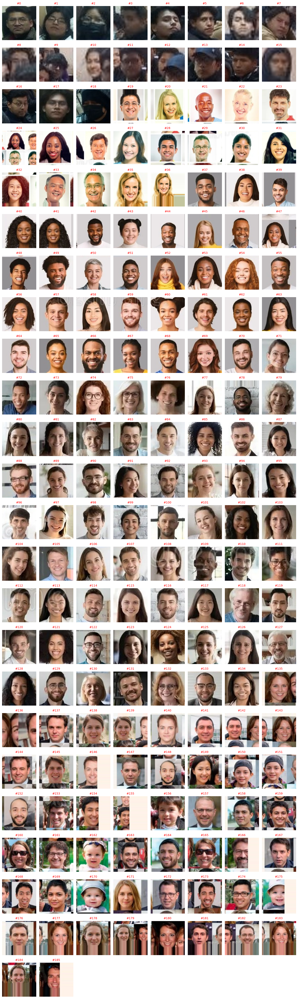

In [3]:
archivos_rostro = sorted(f for f in os.listdir(PERSONAS) if f.lower().endswith(extensiones))
ncols = 8
nrows = (len(archivos_rostro) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 1.8, nrows * 2), squeeze=False)
for ax in axes.flatten():
    ax.axis("off")
for i, (ax, f) in enumerate(zip(axes.flatten(), archivos_rostro)):
    im = cv2.imread(os.path.join(PERSONAS, f))
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
    ax.set_title(f"#{i}", fontsize=10, color="red")
plt.tight_layout(); plt.show()

In [4]:
BORRAR = [24, 36, 41, 136, 139, 142, 151, 155, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185]   # ← escribe aquí los números que NO sean caras, por ejemplo: [3, 7, 12]
for i in BORRAR:
    os.remove(os.path.join(PERSONAS, archivos_rostro[i]))
print(f"Borrados {len(BORRAR)} recortes. Quedan {len(archivos_rostro) - len(BORRAR)}.")

Borrados 18 recortes. Quedan 168.


## 2) Cargar los rostros recortados

In [5]:
nombres, rostros = [], []
for f in sorted(os.listdir(PERSONAS)):
    if f.lower().endswith(extensiones):
        im = cv2.imread(os.path.join(PERSONAS, f))
        if im is None or min(im.shape[:2]) < LADO_MIN_ANALISIS:
            continue
        nombres.append(f)
        rostros.append(im)          # BGR
nombres = np.array(nombres)
n_rostros = len(rostros)
print(f"{n_rostros} rostros cargados desde 'personas/'.")
assert n_rostros >= 4, "Necesito al menos 4 rostros para hacer clustering."

168 rostros cargados desde 'personas/'.


## 3) Extracción de características (análisis profundo de cada rostro)
Cada rostro se normaliza a 128×128 y se describe con varios grupos de características:

| Grupo | Qué mide |
|---|---|
| **color** | tono de piel/ropa/fondo en HSV y Lab (zona central del rostro) |
| **luz** | brillo, contraste y nitidez |
| **textura** | histograma LBP (patrones locales de textura: piel, barba, arrugas) |
| **forma** | HOG (orientación de bordes: contorno de cara, cabello, rasgos) |
| **lentes** | bordes en el puente de la nariz y banda de los ojos, regiones oscuras (marcos) |
| **simetria** | diferencia entre mitad izquierda y derecha |

Los lentes **no** se usan para etiquetar "con/sin lentes": son una familia de características
más dentro del análisis, y el índice de lentes se reporta aparte para interpretar los clusters.

In [6]:
TAM = 128

def extraer_caracteristicas(img_bgr):
    cara = cv2.resize(img_bgr, (TAM, TAM))
    gris = cv2.cvtColor(cara, cv2.COLOR_BGR2GRAY)
    hsv  = cv2.cvtColor(cara, cv2.COLOR_BGR2HSV).astype(np.float32)
    lab  = cv2.cvtColor(cara, cv2.COLOR_BGR2LAB).astype(np.float32)
    f = {}

    # --- color (zona central para reducir fondo) ---
    c = slice(int(TAM * .25), int(TAM * .75))
    f["color_H_media"] = hsv[c, c, 0].mean()
    f["color_S_media"] = hsv[c, c, 1].mean()
    f["color_V_media"] = hsv[c, c, 2].mean()
    f["color_S_std"]   = hsv[c, c, 1].std()
    f["color_V_std"]   = hsv[c, c, 2].std()
    f["color_L_media"] = lab[c, c, 0].mean()
    f["color_a_media"] = lab[c, c, 1].mean()
    f["color_b_media"] = lab[c, c, 2].mean()

    # --- luz / calidad ---
    f["luz_brillo"]    = gris.mean()
    f["luz_contraste"] = gris.std()
    f["luz_nitidez"]   = np.log1p(cv2.Laplacian(gris, cv2.CV_64F).var())

    # --- textura LBP uniforme (10 bins) ---
    lbp = local_binary_pattern(gris, P=8, R=1, method="uniform")
    hist, _ = np.histogram(lbp, bins=np.arange(0, 11), density=True)
    for i, v in enumerate(hist):
        f[f"textura_lbp{i}"] = v

    # --- forma: HOG ---
    vec = hog(gris, orientations=9, pixels_per_cell=(32, 32),
              cells_per_block=(1, 1), feature_vector=True)
    for i, v in enumerate(vec):
        f[f"forma_hog{i}"] = v

    # --- lentes: bordes en puente y banda de ojos ---
    suave = cv2.GaussianBlur(gris, (5, 5), 0)
    bordes = cv2.Canny(suave, 50, 150)
    sobel_y = np.abs(cv2.Sobel(suave, cv2.CV_32F, 0, 1, ksize=3))
    r = lambda a, b: slice(int(TAM * a), int(TAM * b))
    banda   = (r(.25, .50), r(.15, .85))
    puente  = (r(.30, .50), r(.42, .58))
    f["lentes_borde_ojos"]    = bordes[banda].mean() / 255
    f["lentes_borde_puente"]  = bordes[puente].mean() / 255
    f["lentes_horiz_puente"]  = sobel_y[puente].mean() / (sobel_y.mean() + 1e-6)
    f["lentes_zona_oscura"]   = (gris[banda] < 0.6 * np.median(gris)).mean()

    # --- simetría ---
    izq = gris[:, :TAM // 2].astype(np.float32)
    der = gris[:, TAM // 2:][:, ::-1].astype(np.float32)
    f["simetria_asimetria"] = np.abs(izq - der).mean() / 255

    return f

df = pd.DataFrame([extraer_caracteristicas(im) for im in rostros], index=nombres)
print("Matriz de características:", df.shape)

# Índice de lentes (solo para interpretar; promedio de z-scores de las 4 variables de lentes)
cols_lentes = [c for c in df.columns if c.startswith("lentes_")]
z_len = (df[cols_lentes] - df[cols_lentes].mean()) / (df[cols_lentes].std() + 1e-9)
df["indice_lentes"] = z_len.mean(axis=1)

cols_modelo = [c for c in df.columns if c != "indice_lentes"]
grupos = pd.Series([c.split("_")[0] for c in cols_modelo], index=cols_modelo)

# Estandarizar y equilibrar grupos (cada grupo pesa igual sin importar cuántas columnas tenga)
Xz = StandardScaler().fit_transform(df[cols_modelo])
Xw = Xz.copy()
for g in grupos.unique():
    idx = np.where(grupos.values == g)[0]
    Xw[:, idx] *= PESOS.get(g, 1.0) / np.sqrt(len(idx))
print("Grupos y nº de columnas:", grupos.value_counts().to_dict())

Matriz de características: (168, 170)
Grupos y nº de columnas: {'forma': 144, 'textura': 10, 'color': 8, 'lentes': 4, 'luz': 3, 'simetria': 1}


## 4) ¿Cuántos clusters? Codo, Silhouette, Calinski-Harabasz y Davies-Bouldin

k sugerido por Silhouette: 2  |  k usado: 3


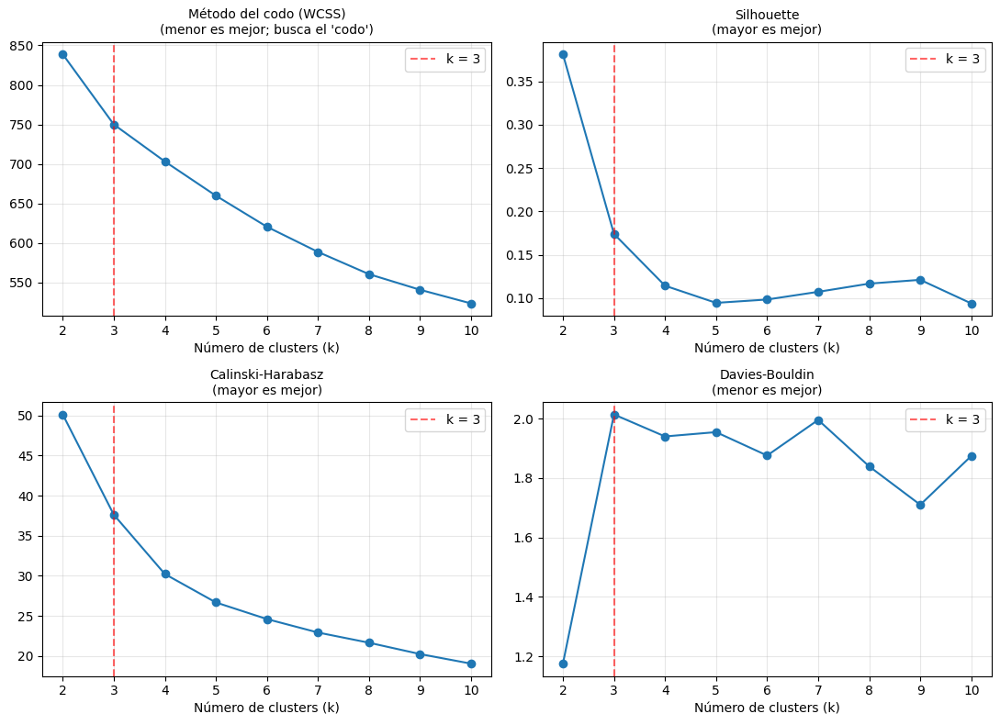

In [7]:
k_max = min(K_MAX, n_rostros - 1)
ks = list(range(2, k_max + 1))
wcss, sil, ch, db = [], [], [], []
for k in ks:
    lab = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(Xw)
    wcss.append(sum(((Xw[lab == c] - Xw[lab == c].mean(0)) ** 2).sum() for c in range(k)))
    sil.append(silhouette_score(Xw, lab))
    ch.append(calinski_harabasz_score(Xw, lab))
    db.append(davies_bouldin_score(Xw, lab))

k_auto = ks[int(np.argmax(sil))]
K = K_ELEGIDO if K_ELEGIDO else k_auto
print(f"k sugerido por Silhouette: {k_auto}  |  k usado: {K}")

fig, axs = plt.subplots(2, 2, figsize=(11, 8))
datos = [("Método del codo (WCSS)", wcss, "menor es mejor; busca el 'codo'"),
         ("Silhouette", sil, "mayor es mejor"),
         ("Calinski-Harabasz", ch, "mayor es mejor"),
         ("Davies-Bouldin", db, "menor es mejor")]
for ax, (titulo, vals, nota) in zip(axs.flatten(), datos):
    ax.plot(ks, vals, "o-")
    ax.axvline(K, color="red", ls="--", alpha=.6, label=f"k = {K}")
    ax.set_title(f"{titulo}\n({nota})", fontsize=10)
    ax.set_xlabel("Número de clusters (k)"); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); guardar("01_metricas_k.png"); plt.show()

## 5) Clustering jerárquico (Ward) y dendrograma

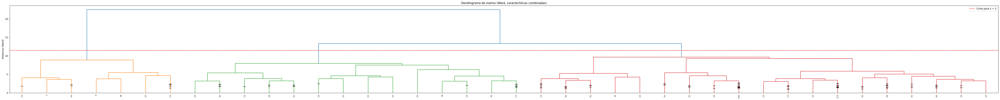

cluster
0    106
1     19
2     43
Name: rostros por cluster, dtype: int64


In [8]:
modelo = AgglomerativeClustering(n_clusters=K, linkage="ward")
etiquetas = modelo.fit_predict(Xw)
df["cluster"] = etiquetas

linked = linkage(Xw, method="ward")
corte = (linked[-K, 2] + linked[-(K - 1), 2]) / 2 if K > 1 else None

plt.figure(figsize=(max(10, n_rostros * 0.35), 6))
if n_rostros <= 60:
    dendrogram(linked, labels=[os.path.splitext(n)[0] for n in nombres],
               leaf_rotation=90, leaf_font_size=7, color_threshold=corte)
else:
    dendrogram(linked, truncate_mode="lastp", p=40, leaf_rotation=90,
               leaf_font_size=8, show_contracted=True, color_threshold=corte)
plt.axhline(corte, color="red", ls="--", label=f"Corte para k = {K}")
plt.title("Dendrograma de rostros (Ward, características combinadas)")
plt.ylabel("Distancia (Ward)"); plt.legend()
plt.tight_layout(); guardar("02_dendrograma.png"); plt.show()

print(df["cluster"].value_counts().sort_index().rename("rostros por cluster"))

## 6) Proyección PCA (PC1 vs PC2)

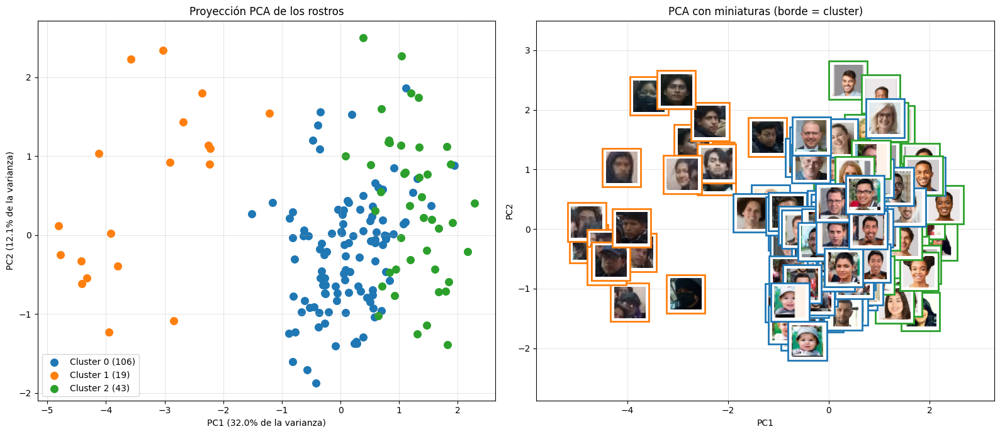

Varianza explicada por PC1+PC2: 44.07%


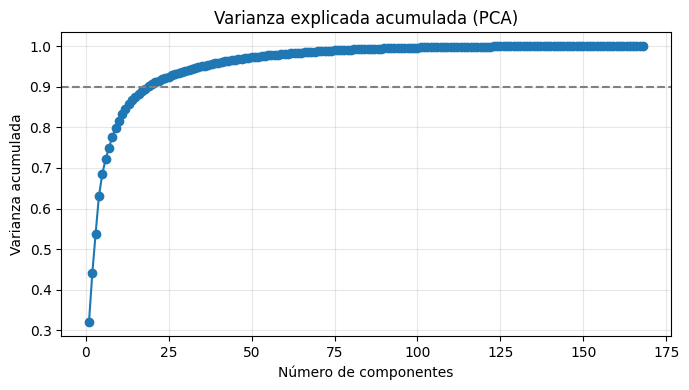

In [9]:
pca = PCA(n_components=2)
X2 = pca.fit_transform(Xw)
colores = plt.cm.tab10(np.linspace(0, 1, 10))

fig, axs = plt.subplots(1, 2, figsize=(16, 7))

# (a) puntos
for k in range(K):
    m = etiquetas == k
    axs[0].scatter(X2[m, 0], X2[m, 1], s=70, color=colores[k % 10], label=f"Cluster {k} ({m.sum()})")
axs[0].set_title("Proyección PCA de los rostros")
axs[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} de la varianza)")
axs[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} de la varianza)")
axs[0].legend(); axs[0].grid(alpha=.3)

# (b) miniaturas de los rostros con borde del color del cluster
for i, im in enumerate(rostros):
    mini = cv2.cvtColor(cv2.resize(im, (40, 40)), cv2.COLOR_BGR2RGB)
    ab = AnnotationBbox(OffsetImage(mini, zoom=0.9), (X2[i, 0], X2[i, 1]), frameon=True,
                        bboxprops=dict(edgecolor=colores[etiquetas[i] % 10], linewidth=2))
    axs[1].add_artist(ab)
axs[1].set_xlim(X2[:, 0].min() - 1, X2[:, 0].max() + 1)
axs[1].set_ylim(X2[:, 1].min() - 1, X2[:, 1].max() + 1)
axs[1].set_title("PCA con miniaturas (borde = cluster)")
axs[1].set_xlabel("PC1"); axs[1].set_ylabel("PC2"); axs[1].grid(alpha=.3)
plt.tight_layout(); guardar("03_pca_2d.png"); plt.show()
print(f"Varianza explicada por PC1+PC2: {pca.explained_variance_ratio_.sum():.2%}")

# Varianza explicada acumulada
pca_full = PCA().fit(Xw)
acum = np.cumsum(pca_full.explained_variance_ratio_)
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(acum) + 1), acum, "o-")
plt.axhline(0.9, color="gray", ls="--"); plt.grid(alpha=.3)
plt.title("Varianza explicada acumulada (PCA)")
plt.xlabel("Número de componentes"); plt.ylabel("Varianza acumulada")
plt.tight_layout(); guardar("04_pca_varianza.png"); plt.show()

## 7) Silhouette por rostro

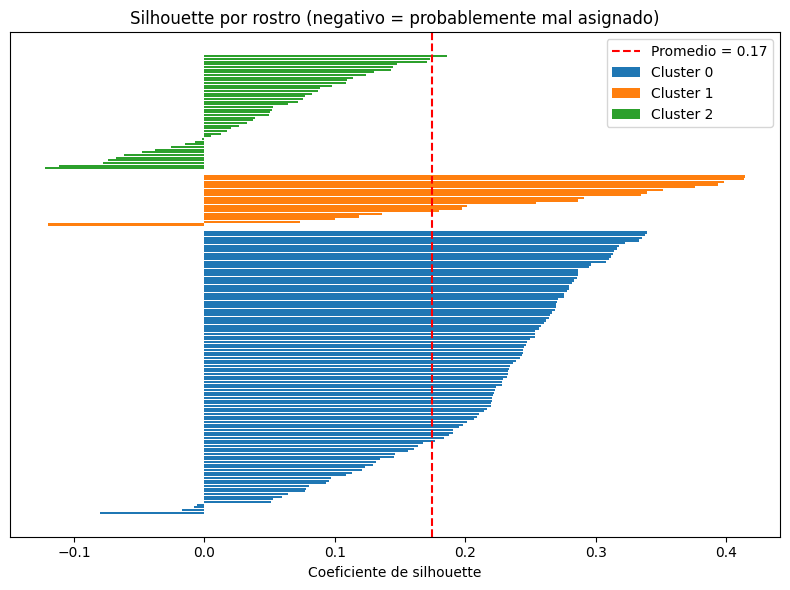

In [10]:
sil_i = silhouette_samples(Xw, etiquetas)
plt.figure(figsize=(8, 6))
y0 = 0
for k in range(K):
    vals = np.sort(sil_i[etiquetas == k])
    plt.barh(range(y0, y0 + len(vals)), vals, color=colores[k % 10], label=f"Cluster {k}")
    y0 += len(vals) + 2
plt.axvline(sil_i.mean(), color="red", ls="--", label=f"Promedio = {sil_i.mean():.2f}")
plt.title("Silhouette por rostro (negativo = probablemente mal asignado)")
plt.xlabel("Coeficiente de silhouette"); plt.yticks([]); plt.legend()
plt.tight_layout(); guardar("05_silhouette_por_rostro.png"); plt.show()

## 8) Rostros de cada cluster

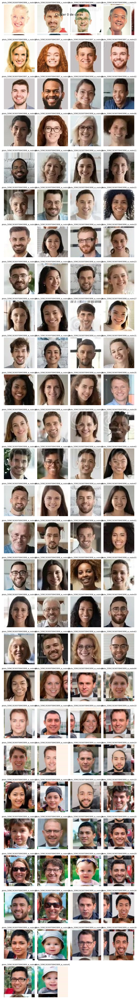

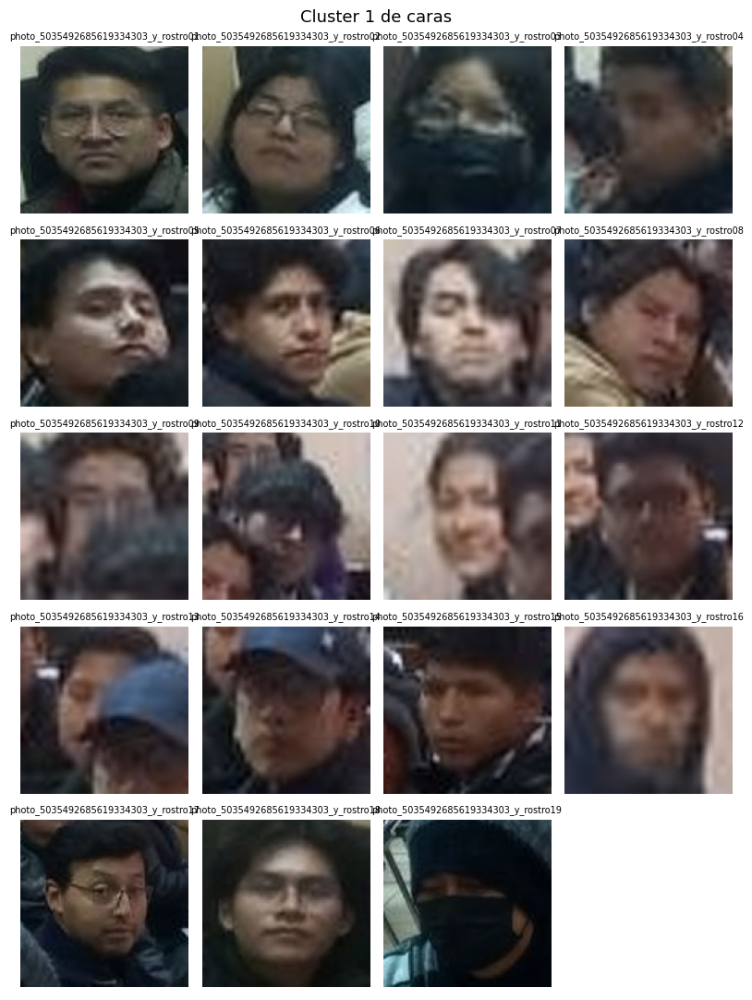

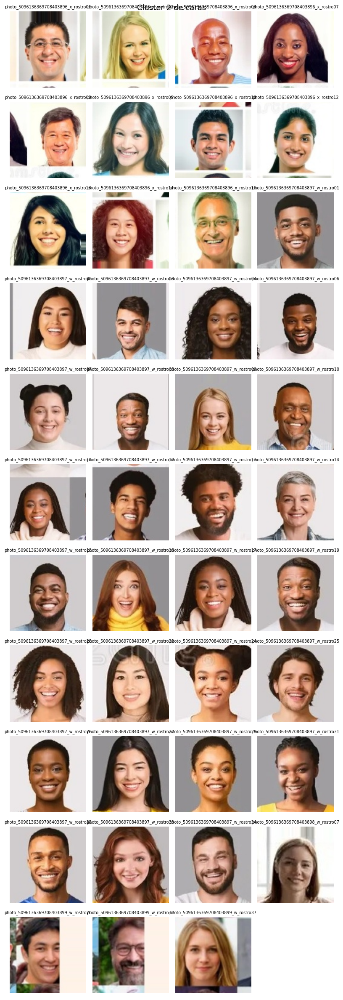

In [11]:
def cuadricula(lista, titulo, ncols=6, archivo=None):
    n = len(lista)
    if n == 0:
        print(f"{titulo}: sin imágenes."); return
    nrows = (n + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 2, nrows * 2.2), squeeze=False)
    for ax in axes.flatten():
        ax.axis("off")
    for ax, (im, nom) in zip(axes.flatten(), lista):
        ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        ax.set_title(os.path.splitext(nom)[0], fontsize=7)
    plt.suptitle(titulo, fontsize=13)
    plt.tight_layout()
    if archivo: guardar(archivo)
    plt.show()

for k in range(K):
    mask = etiquetas == k
    datos_cluster = [(rostros[i], nombres[i]) for i in range(len(nombres)) if mask[i]]
    cuadricula(datos_cluster, f"Cluster {k} de caras", ncols=4, archivo=f"06_cluster_{k}.png")

## 9) Perfil de cada cluster (¿qué lo distingue?) y análisis de lentes

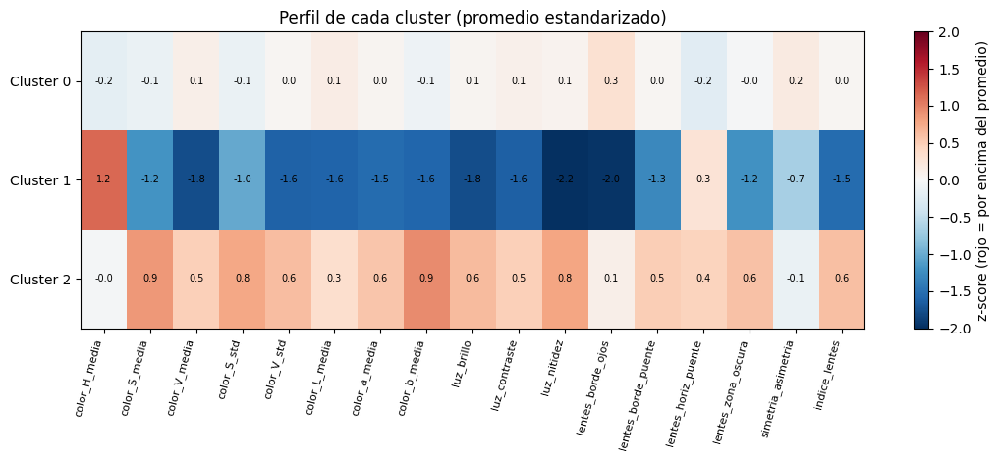

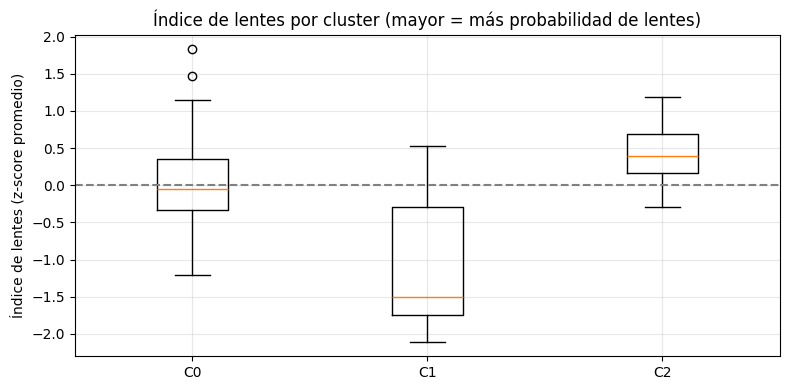

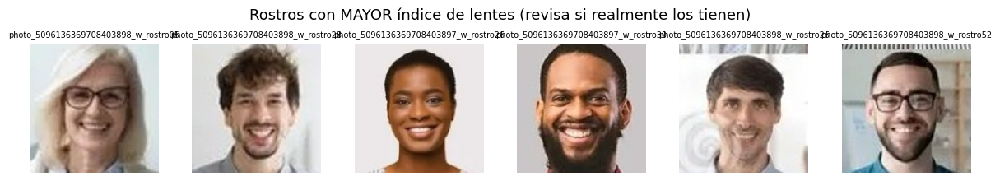

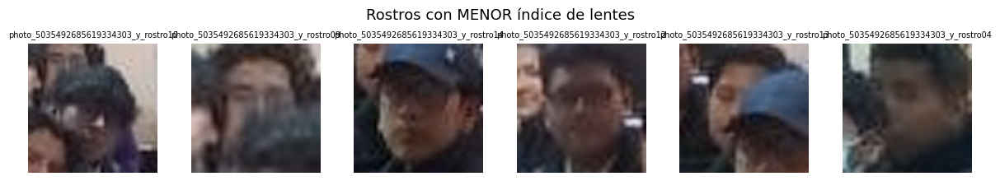

In [12]:
interpretables = [c for c in df.columns
                  if c.startswith(("color_", "luz_", "lentes_", "simetria_")) or c == "indice_lentes"]
z = (df[interpretables] - df[interpretables].mean()) / (df[interpretables].std() + 1e-9)
perfil = z.groupby(df["cluster"]).mean()

fig, ax = plt.subplots(figsize=(11, 0.6 * K + 3))
im_ = ax.imshow(perfil.values, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(len(interpretables))); ax.set_xticklabels(interpretables, rotation=75, ha="right", fontsize=8)
ax.set_yticks(range(K)); ax.set_yticklabels([f"Cluster {k}" for k in range(K)])
for i in range(perfil.shape[0]):
    for j in range(perfil.shape[1]):
        ax.text(j, i, f"{perfil.values[i, j]:.1f}", ha="center", va="center", fontsize=7)
plt.colorbar(im_, label="z-score (rojo = por encima del promedio)")
ax.set_title("Perfil de cada cluster (promedio estandarizado)")
plt.tight_layout(); guardar("07_perfil_clusters.png"); plt.show()

# Distribución del índice de lentes por cluster
plt.figure(figsize=(8, 4))
plt.boxplot([df.loc[df.cluster == k, "indice_lentes"] for k in range(K)])
plt.xticks(range(1, K + 1), [f"C{k}" for k in range(K)])
plt.axhline(0, color="gray", ls="--")
plt.title("Índice de lentes por cluster (mayor = más probabilidad de lentes)")
plt.ylabel("Índice de lentes (z-score promedio)"); plt.grid(alpha=.3)
plt.tight_layout(); guardar("08_indice_lentes.png"); plt.show()

# Validación visual de la heurística de lentes
orden = df["indice_lentes"].sort_values(ascending=False)
pos = {n: i for i, n in enumerate(nombres)}
cuadricula([(rostros[pos[n]], n) for n in orden.index[:6]],
           "Rostros con MAYOR índice de lentes (revisa si realmente los tienen)", archivo="09_top_lentes.png")
cuadricula([(rostros[pos[n]], n) for n in orden.index[-6:]],
           "Rostros con MENOR índice de lentes", archivo="10_bottom_lentes.png")

## 10) Exportar resultados

In [13]:
salida = df[["cluster", "indice_lentes"] + interpretables[:-1]].copy()
salida.insert(0, "rostro", df.index)
salida.to_csv(os.path.join(RESULTADOS, "resultados_clusters.csv"), index=False)
print("Guardado en:", os.path.join(RESULTADOS, "resultados_clusters.csv"))
salida.sort_values("cluster").head(15)

Guardado en: /content/drive/MyDrive/ANALISIS_ROSTROS/resultados/resultados_clusters.csv


,rostro,cluster,indice_lentes,color_H_media,color_S_media,color_V_media,color_S_std,color_V_std,color_L_media,color_a_media,color_b_media,luz_brillo,luz_contraste,luz_nitidez,lentes_borde_ojos,lentes_borde_puente,lentes_horiz_puente,lentes_zona_oscura,simetria_asimetria
photo_5096136369708403896_x_rostro05.jpg,photo_5096136369708403896_x_rostro05.jpg,0,-0.254233,13.691406,95.461670,203.557129,32.332508,37.926601,176.811279,139.669434,150.167236,191.176086,65.628210,6.400523,0.134831,0.073260,1.310678,0.141503,0.114468
photo_5096136369708403896_x_rostro11.jpg,photo_5096136369708403896_x_rostro11.jpg,0,-0.200425,28.238037,63.959473,212.776123,38.402905,40.842392,199.161133,131.673828,144.751221,204.065613,64.025632,6.711047,0.111657,0.131868,1.172908,0.134129,0.198961
photo_5096136369708403896_x_rostro04.jpg,photo_5096136369708403896_x_rostro04.jpg,0,-1.116618,13.843750,67.710449,245.608398,18.847160,17.118198,217.211914,139.330811,145.227539,230.486084,26.472433,5.207202,0.058638,0.086081,1.041798,0.016503,0.045376
photo_5096136369708403897_w_rostro23.jpg,photo_5096136369708403897_w_rostro23.jpg,0,-0.123833,7.600830,87.317139,211.082275,32.188164,42.590683,177.897461,145.374268,144.060547,168.504517,48.163612,6.149383,0.129916,0.113553,1.205741,0.145014,0.100723
photo_5096136369708403897_w_rostro30.jpg,photo_5096136369708403897_w_rostro30.jpg,0,1.151195,10.210938,126.173584,158.540039,40.192318,65.113914,128.031250,144.187012,149.388672,138.788635,66.014951,6.637937,0.164677,0.163004,1.976631,0.354284,0.128818
photo_5096136369708403897_w_rostro21.jpg,photo_5096136369708403897_w_rostro21.jpg,0,0.287514,9.394531,111.024902,204.071533,33.191349,46.797577,166.862549,146.724365,150.688721,160.701355,52.974199,6.240431,0.124298,0.111722,1.411134,0.346208,0.138972
photo_5096136369708403896_x_rostro17.jpg,photo_5096136369708403896_x_rostro17.jpg,0,0.131409,14.268311,119.185303,210.702393,38.928722,56.687496,177.371338,141.026611,157.142822,189.419556,57.061705,6.399803,0.129213,0.100733,1.457606,0.258778,0.142183
photo_5096136369708403896_x_rostro15.jpg,photo_5096136369708403896_x_rostro15.jpg,0,-0.266399,10.214111,106.167236,203.832275,26.276190,32.326275,166.098389,147.524170,150.544434,180.932556,59.678829,6.467622,0.114466,0.111722,1.511371,0.053371,0.218425
photo_5096136369708403897_w_rostro28.jpg,photo_5096136369708403897_w_rostro28.jpg,0,-0.430539,7.260986,71.520752,218.945312,26.206009,38.879372,189.715332,142.959473,141.309570,181.129456,47.224806,5.983743,0.112360,0.100733,0.940133,0.157303,0.097428
photo_5096136369708403897_w_rostro18.jpg,photo_5096136369708403897_w_rostro18.jpg,0,-0.709308,10.271484,105.609863,217.938721,50.877884,43.423637,182.306396,144.973877,151.321777,149.713074,66.640437,6.152518,0.117275,0.104396,0.719434,0.031250,0.077276


11) K-Means: codo, Silhouette, Calinski-Harabasz y Davies-Bouldin
K-Means necesita que tú indiques k; por eso se evalúan varios valores con las mismas métricas del jerárquico. Las curvas grises punteadas son las del clustering jerárquico (Ward), para comparar a simple vista.

Parámetros nuevos (ajústalos en la celda siguiente): K_KMEANS (None = usa el mismo K del jerárquico, lo más justo para comparar), MIN_SAMPLES, EPS_ELEGIDO, MAX_RUIDO (para DBSCAN) y N_BOOT (remuestreos para medir estabilidad).

In [14]:
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from IPython.display import display

# ---------------- Parámetros nuevos ----------------
K_KMEANS    = None   # None = mismo K que el jerárquico. O pon un número, ej. 4
MIN_SAMPLES = 5      # DBSCAN: vecinos mínimos para formar un núcleo (prueba 3-10)
EPS_ELEGIDO = None   # DBSCAN: None = automático (mejor silhouette con ruido <= MAX_RUIDO). O pon un valor
MAX_RUIDO   = 0.40   # DBSCAN: máximo de rostros "ruido" aceptado al elegir eps automáticamente (40 %)
N_BOOT      = 20     # nº de remuestreos (80 % de los rostros) para medir la estabilidad

etiquetas_jer = etiquetas.copy()          # etiquetas del jerárquico (sección 5)
K_KM = K_KMEANS if K_KMEANS else K

# ---------------- Utilidades compartidas ----------------
def codo_auto(x, y):
    """Punto de mayor distancia a la recta que une el primer y el último punto (criterio del codo)."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    xn = (x - x.min()) / (x.max() - x.min() + 1e-12)
    yn = (y - y.min()) / (y.max() - y.min() + 1e-12)
    d = np.abs((yn[-1] - yn[0]) * xn - (xn[-1] - xn[0]) * yn + xn[-1] * yn[0] - yn[-1] * xn[0])
    return x[int(np.argmax(d))]

def color_cluster(k):  return "gray" if k == -1 else colores[k % 10]
def nombre_cluster(k): return "Ruido" if k == -1 else f"Cluster {k}"

def graficar_pca(etiq, titulo, archivo, centros=None):
    """PCA 2D: izquierda puntos, derecha miniaturas de rostros (borde = cluster; gris = ruido)."""
    fig, axs = plt.subplots(1, 2, figsize=(16, 7))
    for k in sorted(set(etiq)):
        m = etiq == k
        axs[0].scatter(X2[m, 0], X2[m, 1], s=70, color=color_cluster(k),
                       marker="x" if k == -1 else "o", label=f"{nombre_cluster(k)} ({m.sum()})")
    if centros is not None:
        c2 = pca.transform(centros)
        axs[0].scatter(c2[:, 0], c2[:, 1], marker="X", s=250, c="black", edgecolors="white", label="Centroides")
    axs[0].set_title(titulo)
    axs[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
    axs[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
    axs[0].legend(); axs[0].grid(alpha=.3)
    for i, im in enumerate(rostros):
        mini = cv2.cvtColor(cv2.resize(im, (40, 40)), cv2.COLOR_BGR2RGB)
        ab = AnnotationBbox(OffsetImage(mini, zoom=0.9), (X2[i, 0], X2[i, 1]), frameon=True,
                            bboxprops=dict(edgecolor=color_cluster(etiq[i]), linewidth=2))
        axs[1].add_artist(ab)
    axs[1].set_xlim(X2[:, 0].min() - 1, X2[:, 0].max() + 1)
    axs[1].set_ylim(X2[:, 1].min() - 1, X2[:, 1].max() + 1)
    axs[1].set_title(titulo + " – miniaturas (borde = cluster)")
    axs[1].set_xlabel("PC1"); axs[1].set_ylabel("PC2"); axs[1].grid(alpha=.3)
    plt.tight_layout(); guardar(archivo); plt.show()

def graficar_silhouette(etiq, titulo, archivo):
    """Silhouette por rostro (el ruido de DBSCAN se excluye)."""
    m = etiq != -1
    if len(set(etiq[m])) < 2:
        print("Silhouette por rostro: se necesitan al menos 2 clusters sin contar ruido."); return
    s = silhouette_samples(Xw[m], etiq[m])
    plt.figure(figsize=(8, 6)); y0 = 0
    for k in sorted(set(etiq[m])):
        vals = np.sort(s[etiq[m] == k])
        plt.barh(range(y0, y0 + len(vals)), vals, color=color_cluster(k), label=nombre_cluster(k))
        y0 += len(vals) + 2
    plt.axvline(s.mean(), color="red", ls="--", label=f"Promedio = {s.mean():.2f}")
    plt.title(titulo); plt.xlabel("Coeficiente de silhouette"); plt.yticks([]); plt.legend()
    plt.tight_layout(); guardar(archivo); plt.show()

def grid_clusters(etiq, prefijo, archivo_prefijo):
    for k in sorted(set(etiq)):
        lista = [(rostros[i], nombres[i]) for i in range(len(nombres)) if etiq[i] == k]
        cuadricula(lista, f"{prefijo} – {nombre_cluster(k)} ({len(lista)} rostros)", ncols=4,
                   archivo=f"{archivo_prefijo}_{'ruido' if k == -1 else k}.png")

# Métricas internas (el ruido -1 se excluye); las usan DBSCAN, HDBSCAN, OPTICS y la comparación
def metricas_internas(X, lab):
    m = lab != -1
    if len(set(lab[m])) < 2 or m.sum() <= len(set(lab[m])):
        return dict(silhouette=np.nan, calinski=np.nan, davies_bouldin=np.nan)
    return dict(silhouette=silhouette_score(X[m], lab[m]),
                calinski=calinski_harabasz_score(X[m], lab[m]),
                davies_bouldin=davies_bouldin_score(X[m], lab[m]))

print(f"K-Means se ajustará con k = {K_KM}")

K-Means se ajustará con k = 3


K-Means → codo: k=5 | Silhouette: k=2 | Calinski-Harabasz: k=2 | Davies-Bouldin: k=2 | k usado: 3


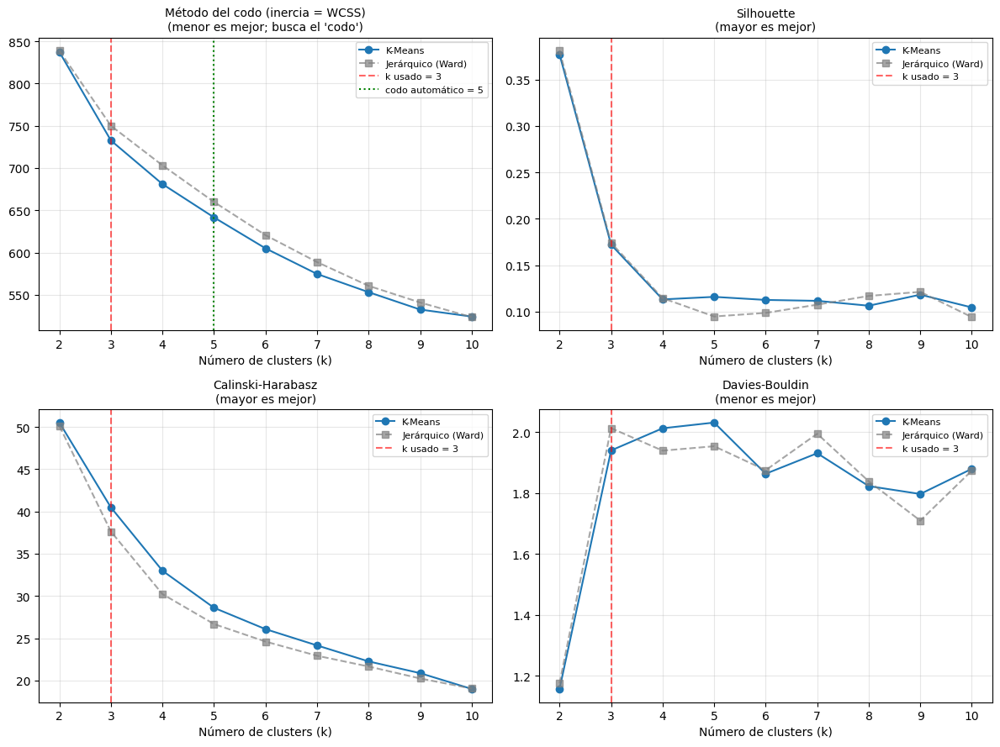

In [15]:
km_in, km_sil, km_ch, km_db = [], [], [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xw)
    km_in.append(km.inertia_)
    km_sil.append(silhouette_score(Xw, km.labels_))
    km_ch.append(calinski_harabasz_score(Xw, km.labels_))
    km_db.append(davies_bouldin_score(Xw, km.labels_))

k_codo_km = int(codo_auto(ks, km_in))
k_sil_km  = ks[int(np.argmax(km_sil))]
k_ch_km   = ks[int(np.argmax(km_ch))]
k_db_km   = ks[int(np.argmin(km_db))]
print(f"K-Means → codo: k={k_codo_km} | Silhouette: k={k_sil_km} | Calinski-Harabasz: k={k_ch_km} | Davies-Bouldin: k={k_db_km} | k usado: {K_KM}")

fig, axs = plt.subplots(2, 2, figsize=(12, 9))
paneles = [("Método del codo (inercia = WCSS)", km_in, wcss, "menor es mejor; busca el 'codo'"),
           ("Silhouette", km_sil, sil, "mayor es mejor"),
           ("Calinski-Harabasz", km_ch, ch, "mayor es mejor"),
           ("Davies-Bouldin", km_db, db, "menor es mejor")]
for ax, (titulo, vals, vals_jer, nota) in zip(axs.flatten(), paneles):
    ax.plot(ks, vals, "o-", label="K-Means")
    ax.plot(ks, vals_jer, "s--", color="gray", alpha=.7, label="Jerárquico (Ward)")
    ax.axvline(K_KM, color="red", ls="--", alpha=.6, label=f"k usado = {K_KM}")
    if "codo" in titulo:
        ax.axvline(k_codo_km, color="green", ls=":", label=f"codo automático = {k_codo_km}")
    ax.set_title(f"{titulo}\n({nota})", fontsize=10)
    ax.set_xlabel("Número de clusters (k)"); ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); guardar("11_kmeans_metricas_k.png"); plt.show()

0    18
1    94
2    56
Name: rostros por cluster (K-Means), dtype: int64
Inercia final: 732.59


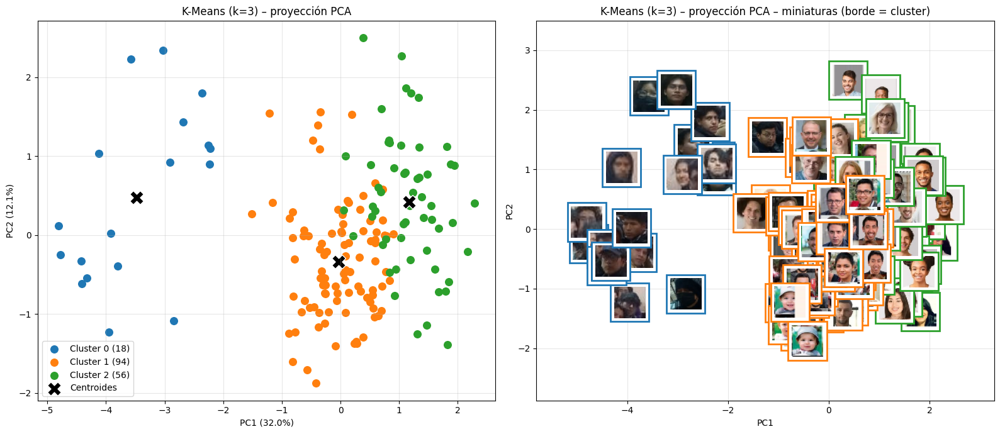

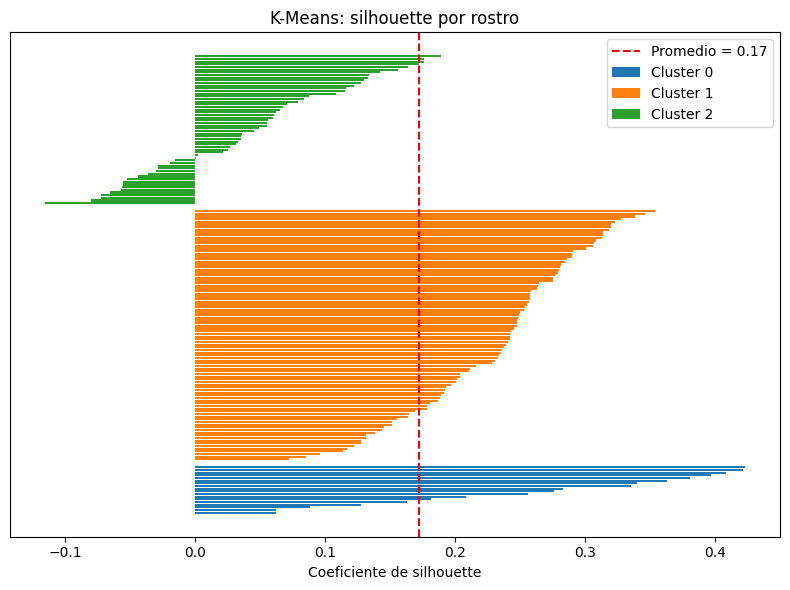

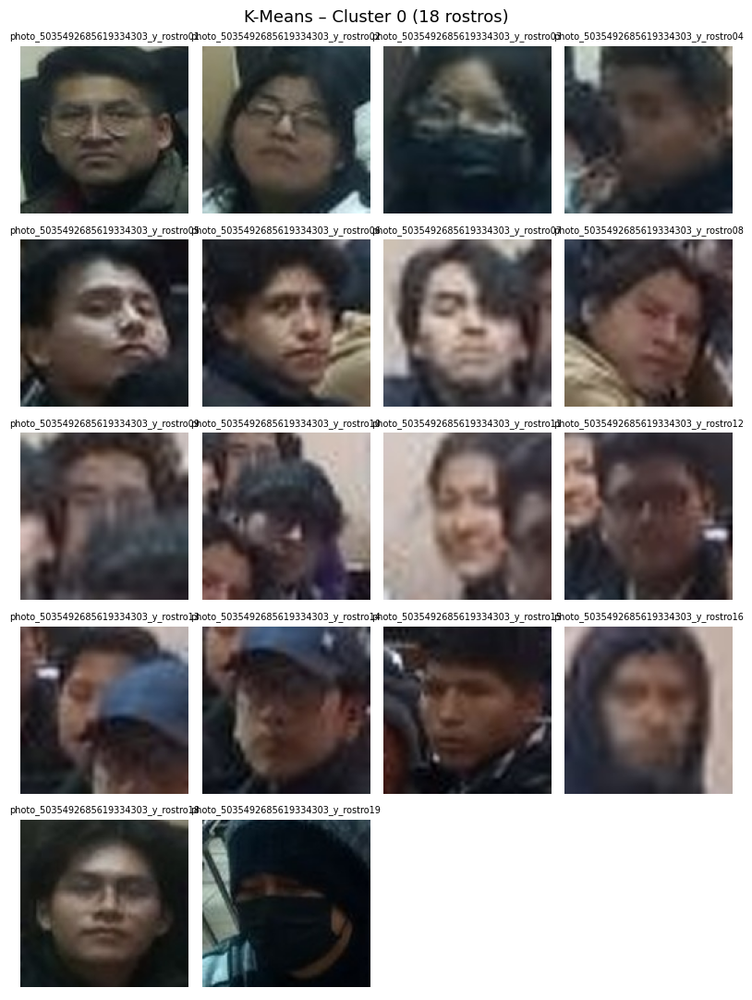

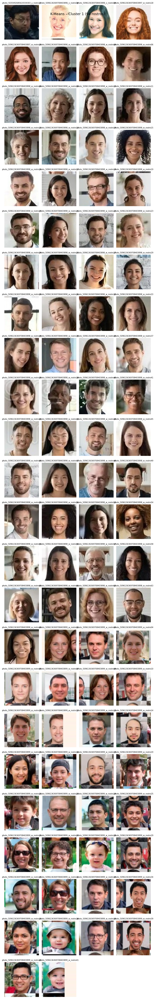

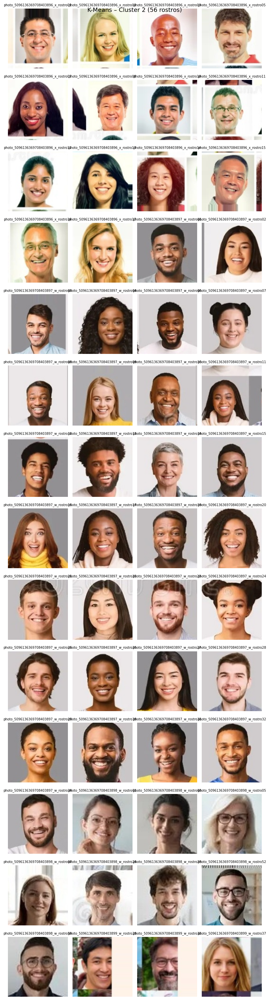

In [16]:
kmeans = KMeans(n_clusters=K_KM, n_init=10, random_state=42).fit(Xw)
etiquetas_km = kmeans.labels_
df["cluster_kmeans"] = etiquetas_km
print(pd.Series(etiquetas_km).value_counts().sort_index().rename("rostros por cluster (K-Means)"))
print(f"Inercia final: {kmeans.inertia_:.2f}")

graficar_pca(etiquetas_km, f"K-Means (k={K_KM}) – proyección PCA", "12_kmeans_pca.png", centros=kmeans.cluster_centers_)
graficar_silhouette(etiquetas_km, "K-Means: silhouette por rostro", "13_kmeans_silhouette.png")
grid_clusters(etiquetas_km, "K-Means", "14_kmeans_cluster")

## 12) DBSCAN: gráfica del codo (k-distancia), Calinski-Harabasz y clusters
DBSCAN **no recibe k**: recibe `eps` (radio de vecindad) y `min_samples`. Detecta solos los clusters y marca como **ruido (-1)**
a los rostros que no pertenecen a ninguna zona densa.

- **Codo de DBSCAN = gráfica de k-distancia**: se ordena la distancia de cada rostro a su vecino número `MIN_SAMPLES`; el `eps` ideal está en el "codo" de la curva.
- Se barre `eps` y se calcula nº de clusters, % de ruido, Silhouette, Calinski-Harabasz y Davies-Bouldin (las tres métricas se calculan **sin contar el ruido**, por eso hay que mirar también el % de ruido).
- Con 170 características (y 144 de HOG) DBSCAN sufre la *maldición de la dimensionalidad*: las distancias se parecen entre sí, y es normal que forme un cluster enorme + mucho ruido.

eps del codo (k-distancia): 2.287 | eps usado: 1.864  (mejor silhouette con ruido <= 40%) | min_samples = 5


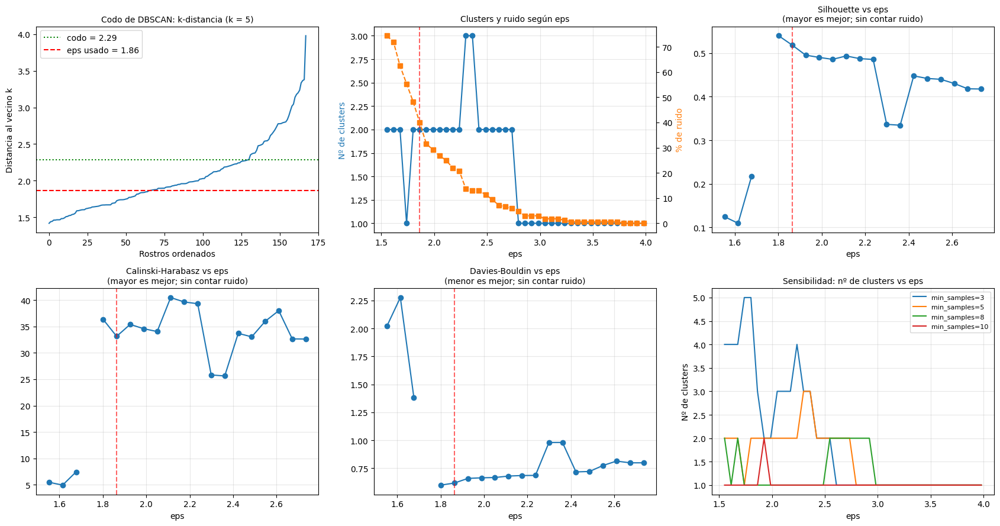

,eps,n_clusters,ruido,silhouette,calinski,davies_bouldin
0,1.553,2,0.744,0.125,5.446,2.019
1,1.615,2,0.720,0.110,4.908,2.276
2,1.677,2,0.625,0.218,7.419,1.384
3,1.739,1,0.554,NaN,NaN,NaN
4,1.801,2,0.482,0.540,36.366,0.599
5,1.864,2,0.399,0.518,33.145,0.618
6,1.926,2,0.315,0.495,35.414,0.659
7,1.988,2,0.292,0.490,34.596,0.665
8,2.050,2,0.268,0.486,34.058,0.667
9,2.112,2,0.250,0.493,40.510,0.680


In [17]:
# ---------- Codo: gráfica de k-distancia ----------
vec = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Xw)
k_dist = np.sort(vec.kneighbors(Xw)[0][:, -1])
eps_codo = float(k_dist[int(codo_auto(np.arange(len(k_dist)), k_dist))])

# ---------- Barrido de eps ----------
eps_grid = np.linspace(np.percentile(k_dist, 10), k_dist.max(), 40)
filas = []
for e in eps_grid:
    lab = DBSCAN(eps=e, min_samples=MIN_SAMPLES).fit_predict(Xw)
    m = lab != -1
    n_cl = len(set(lab[m]))
    fila = dict(eps=e, n_clusters=n_cl, ruido=1 - m.mean(), silhouette=np.nan, calinski=np.nan, davies_bouldin=np.nan)
    if n_cl >= 2 and m.sum() > n_cl:
        fila.update(silhouette=silhouette_score(Xw[m], lab[m]),
                    calinski=calinski_harabasz_score(Xw[m], lab[m]),
                    davies_bouldin=davies_bouldin_score(Xw[m], lab[m]))
    filas.append(fila)
df_eps = pd.DataFrame(filas)

# ---------- Elección de eps ----------
validos = df_eps[(df_eps.n_clusters >= 2) & (df_eps.ruido <= MAX_RUIDO)].dropna(subset=["silhouette"])
if EPS_ELEGIDO is not None:
    eps_db, origen = float(EPS_ELEGIDO), "manual"
elif len(validos):
    eps_db, origen = float(validos.loc[validos.silhouette.idxmax(), "eps"]), f"mejor silhouette con ruido <= {MAX_RUIDO:.0%}"
else:
    eps_db, origen = eps_codo, "codo de k-distancia (ningún eps dio >= 2 clusters con poco ruido)"
print(f"eps del codo (k-distancia): {eps_codo:.3f} | eps usado: {eps_db:.3f}  ({origen}) | min_samples = {MIN_SAMPLES}")

# ---------- Gráficas ----------
fig, axs = plt.subplots(2, 3, figsize=(17, 9))
axs[0, 0].plot(k_dist); axs[0, 0].axhline(eps_codo, color="green", ls=":", label=f"codo = {eps_codo:.2f}")
axs[0, 0].axhline(eps_db, color="red", ls="--", label=f"eps usado = {eps_db:.2f}")
axs[0, 0].set_title(f"Codo de DBSCAN: k-distancia (k = {MIN_SAMPLES})", fontsize=10)
axs[0, 0].set_xlabel("Rostros ordenados"); axs[0, 0].set_ylabel("Distancia al vecino k"); axs[0, 0].legend()

axs[0, 1].plot(df_eps.eps, df_eps.n_clusters, "o-", color="tab:blue")
axs[0, 1].set_ylabel("Nº de clusters", color="tab:blue")
ax2 = axs[0, 1].twinx(); ax2.plot(df_eps.eps, df_eps.ruido * 100, "s--", color="tab:orange")
ax2.set_ylabel("% de ruido", color="tab:orange")
axs[0, 1].set_title("Clusters y ruido según eps", fontsize=10)

for ax, col, titulo, nota in [(axs[0, 2], "silhouette", "Silhouette vs eps", "mayor es mejor"),
                              (axs[1, 0], "calinski", "Calinski-Harabasz vs eps", "mayor es mejor"),
                              (axs[1, 1], "davies_bouldin", "Davies-Bouldin vs eps", "menor es mejor")]:
    ax.plot(df_eps.eps, df_eps[col], "o-")
    ax.set_title(f"{titulo}\n({nota}; sin contar ruido)", fontsize=10)
for ax in (axs[0, 1], axs[0, 2], axs[1, 0], axs[1, 1]):
    ax.axvline(eps_db, color="red", ls="--", alpha=.6); ax.set_xlabel("eps"); ax.grid(alpha=.3)

# sensibilidad a min_samples
for ms in (3, 5, 8, 10):
    ncl = []
    for e in eps_grid:
        lab = DBSCAN(eps=e, min_samples=ms).fit_predict(Xw)
        ncl.append(len(set(lab[lab != -1])))
    axs[1, 2].plot(eps_grid, ncl, label=f"min_samples={ms}")
axs[1, 2].set_title("Sensibilidad: nº de clusters vs eps", fontsize=10)
axs[1, 2].set_xlabel("eps"); axs[1, 2].set_ylabel("Nº de clusters"); axs[1, 2].legend(fontsize=8); axs[1, 2].grid(alpha=.3)
plt.tight_layout(); guardar("15_dbscan_metricas_eps.png"); plt.show()

display(df_eps.round(3))

DBSCAN encontró 2 clusters y 67 rostros de ruido (39.9%).
-1    67
 0     5
 1    96
Name: rostros por cluster (-1 = ruido), dtype: int64


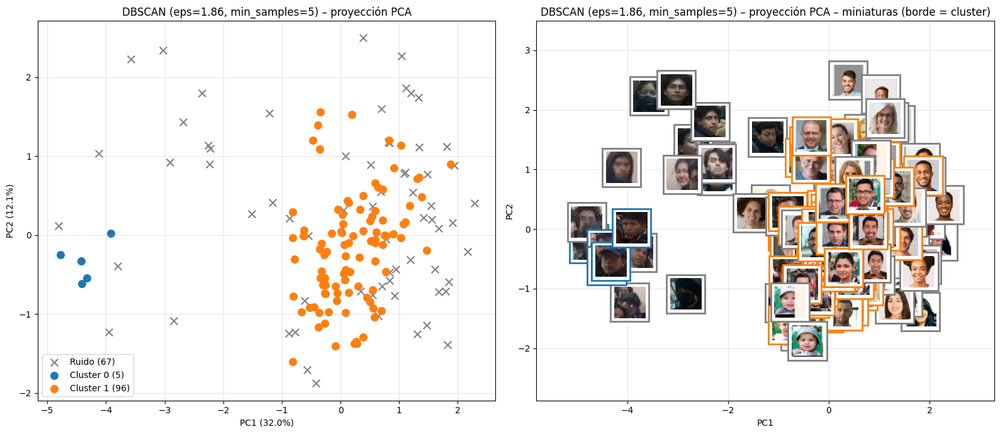

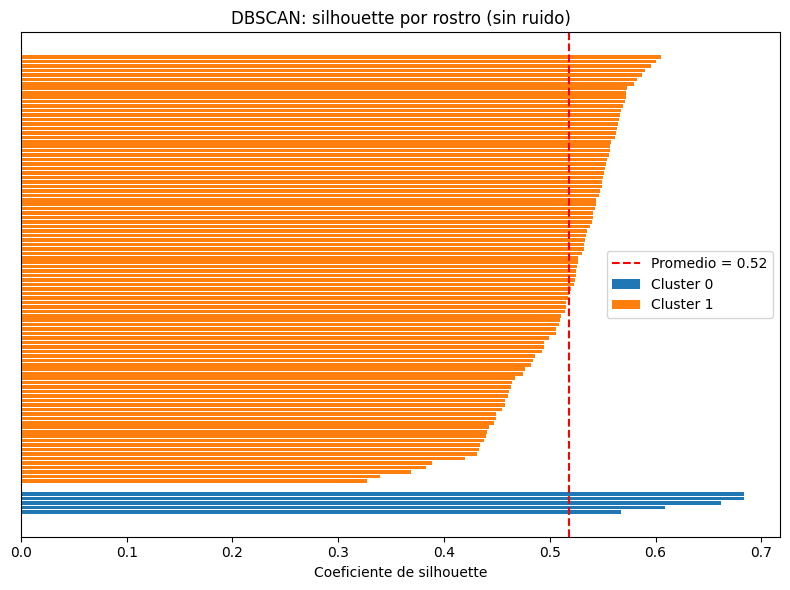

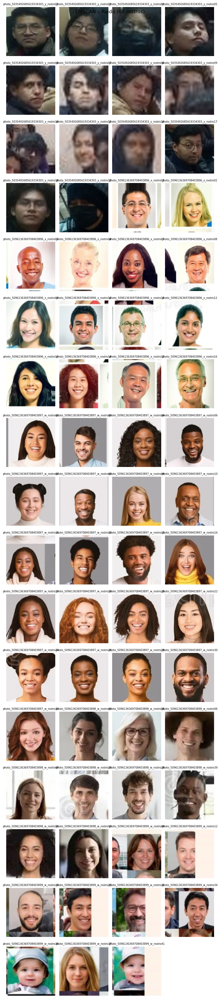

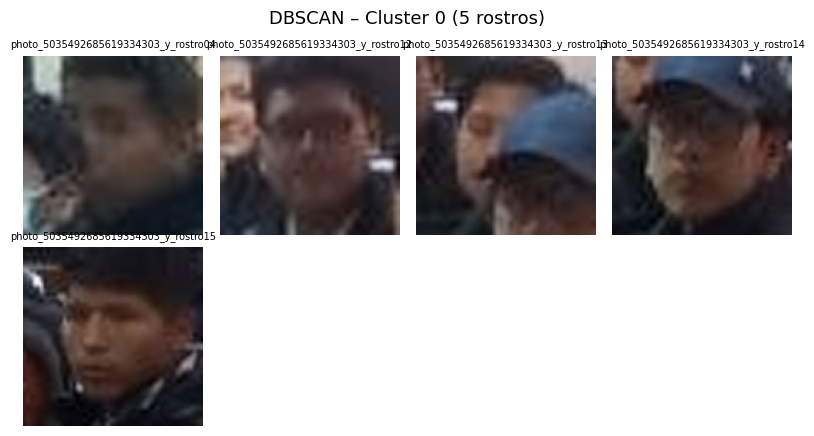

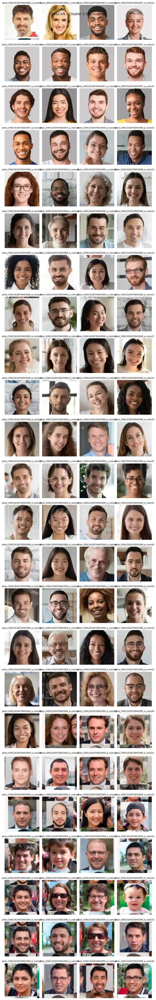

In [18]:
dbscan = DBSCAN(eps=eps_db, min_samples=MIN_SAMPLES).fit(Xw)
etiquetas_db = dbscan.labels_
df["cluster_dbscan"] = etiquetas_db
n_cl_db = len(set(etiquetas_db[etiquetas_db != -1]))
print(f"DBSCAN encontró {n_cl_db} clusters y {(etiquetas_db == -1).sum()} rostros de ruido ({(etiquetas_db == -1).mean():.1%}).")
print(pd.Series(etiquetas_db).value_counts().sort_index().rename("rostros por cluster (-1 = ruido)"))

graficar_pca(etiquetas_db, f"DBSCAN (eps={eps_db:.2f}, min_samples={MIN_SAMPLES}) – proyección PCA", "16_dbscan_pca.png")
graficar_silhouette(etiquetas_db, "DBSCAN: silhouette por rostro (sin ruido)", "17_dbscan_silhouette.png")
grid_clusters(etiquetas_db, "DBSCAN", "18_dbscan_cluster")

## 13) HDBSCAN: barrido de `min_cluster_size`, métricas y clusters
HDBSCAN es la versión **jerárquica y de densidad variable** de DBSCAN: no necesita `eps` (el gran dolor de cabeza de DBSCAN en 170 dimensiones),
y encuentra solo los clusters más **estables** a lo largo de todas las escalas de densidad. Los parámetros son:

- `min_cluster_size`: tamaño mínimo para considerar un grupo como cluster (es el parámetro importante; es el análogo del "codo").
- `min_samples`: qué tan conservador es (`None` = igual a `min_cluster_size`; un valor menor deja menos ruido).

Igual que en DBSCAN, los rostros que no pertenecen a ningún grupo estable se marcan como **ruido (-1)**, y las métricas internas se calculan **sin contar el ruido**
(hay que mirar también el % de ruido). Además HDBSCAN entrega una **probabilidad de pertenencia** por rostro (1 = núcleo del cluster, cercano a 0 = borde).

min_cluster_size usado: 6  (mejor silhouette con ruido <= 40%) | min_samples = igual a min_cluster_size


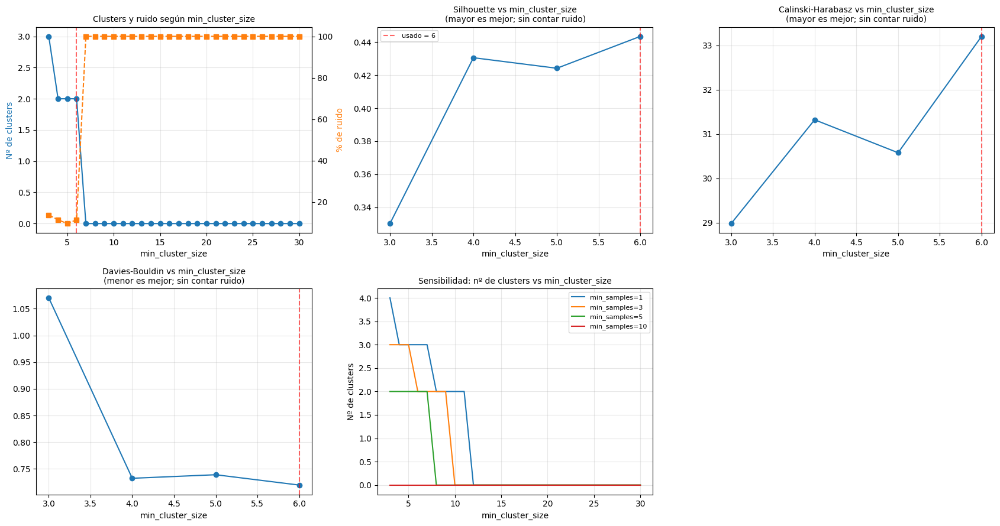

,min_cluster_size,n_clusters,ruido,silhouette,calinski,davies_bouldin
0,3,3,0.137,0.330,28.981,1.070
1,4,2,0.113,0.431,31.321,0.732
2,5,2,0.095,0.424,30.577,0.739
3,6,2,0.113,0.444,33.202,0.720
4,7,0,1.000,NaN,NaN,NaN
5,8,0,1.000,NaN,NaN,NaN
6,9,0,1.000,NaN,NaN,NaN
7,10,0,1.000,NaN,NaN,NaN
8,11,0,1.000,NaN,NaN,NaN
9,12,0,1.000,NaN,NaN,NaN


In [19]:
# ---------------- Parámetros nuevos (HDBSCAN) ----------------
MCS_ELEGIDO     = None   # HDBSCAN: min_cluster_size. None = automático (mejor silhouette con ruido <= MAX_RUIDO). O pon un número, ej. 8
MIN_SAMPLES_HDB = None   # HDBSCAN: None = igual a min_cluster_size. Un valor menor (3-5) deja menos ruido

try:
    from sklearn.cluster import HDBSCAN          # scikit-learn >= 1.3
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "hdbscan"], check=True)
    from hdbscan import HDBSCAN

# ---------- Barrido de min_cluster_size ----------
mcs_grid = list(range(3, max(4, min(30, n_rostros // 4)) + 1))
filas = []
for m_ in mcs_grid:
    lab = HDBSCAN(min_cluster_size=m_, min_samples=MIN_SAMPLES_HDB).fit_predict(Xw)
    mk = lab != -1
    fila = dict(min_cluster_size=m_, n_clusters=len(set(lab[mk])), ruido=1 - mk.mean())
    fila.update(metricas_internas(Xw, lab))
    filas.append(fila)
df_mcs = pd.DataFrame(filas)

# ---------- Elección de min_cluster_size ----------
validos = df_mcs[(df_mcs.n_clusters >= 2) & (df_mcs.ruido <= MAX_RUIDO)].dropna(subset=["silhouette"])
if MCS_ELEGIDO is not None:
    mcs_hdb, origen = int(MCS_ELEGIDO), "manual"
elif len(validos):
    mcs_hdb, origen = int(validos.loc[validos.silhouette.idxmax(), "min_cluster_size"]), f"mejor silhouette con ruido <= {MAX_RUIDO:.0%}"
else:
    mcs_hdb, origen = 5, "valor por defecto (ningún valor dio >= 2 clusters con poco ruido)"
print(f"min_cluster_size usado: {mcs_hdb}  ({origen}) | min_samples = {MIN_SAMPLES_HDB if MIN_SAMPLES_HDB else 'igual a min_cluster_size'}")

# ---------- Gráficas ----------
fig, axs = plt.subplots(2, 3, figsize=(17, 9))
axs[0, 0].plot(df_mcs.min_cluster_size, df_mcs.n_clusters, "o-", color="tab:blue")
axs[0, 0].set_ylabel("Nº de clusters", color="tab:blue")
ax2 = axs[0, 0].twinx(); ax2.plot(df_mcs.min_cluster_size, df_mcs.ruido * 100, "s--", color="tab:orange")
ax2.set_ylabel("% de ruido", color="tab:orange")
axs[0, 0].set_title("Clusters y ruido según min_cluster_size", fontsize=10)
for ax, col, titulo, nota in [(axs[0, 1], "silhouette", "Silhouette", "mayor es mejor"),
                              (axs[0, 2], "calinski", "Calinski-Harabasz", "mayor es mejor"),
                              (axs[1, 0], "davies_bouldin", "Davies-Bouldin", "menor es mejor")]:
    ax.plot(df_mcs.min_cluster_size, df_mcs[col], "o-")
    ax.set_title(f"{titulo} vs min_cluster_size\n({nota}; sin contar ruido)", fontsize=10)
for ax in (axs[0, 0], axs[0, 1], axs[0, 2], axs[1, 0]):
    ax.axvline(mcs_hdb, color="red", ls="--", alpha=.6, label=f"usado = {mcs_hdb}")
    ax.set_xlabel("min_cluster_size"); ax.grid(alpha=.3)
axs[0, 1].legend(fontsize=8)

# sensibilidad a min_samples
for ms in (1, 3, 5, 10):
    ncl = []
    for m_ in mcs_grid:
        lab = HDBSCAN(min_cluster_size=m_, min_samples=ms).fit_predict(Xw)
        ncl.append(len(set(lab[lab != -1])))
    axs[1, 1].plot(mcs_grid, ncl, label=f"min_samples={ms}")
axs[1, 1].set_title("Sensibilidad: nº de clusters vs min_cluster_size", fontsize=10)
axs[1, 1].set_xlabel("min_cluster_size"); axs[1, 1].set_ylabel("Nº de clusters")
axs[1, 1].legend(fontsize=8); axs[1, 1].grid(alpha=.3)
axs[1, 2].axis("off")      # aquí va el histograma de probabilidades (se dibuja en la siguiente celda)
plt.tight_layout(); guardar("23_hdbscan_metricas.png"); plt.show()

display(df_mcs.round(3))

HDBSCAN encontró 2 clusters y 19 rostros de ruido (11.3%).
-1     19
 0    142
 1      7
Name: rostros por cluster (-1 = ruido), dtype: int64


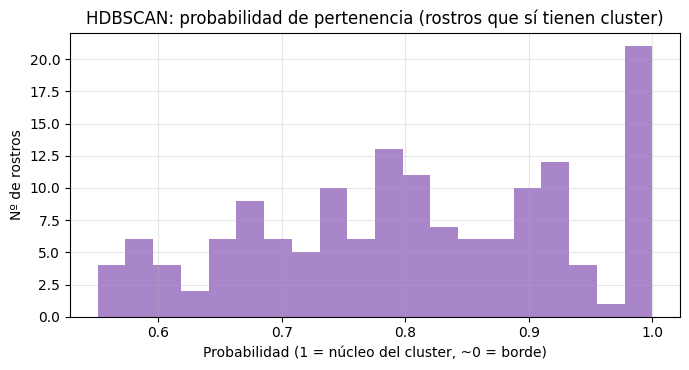

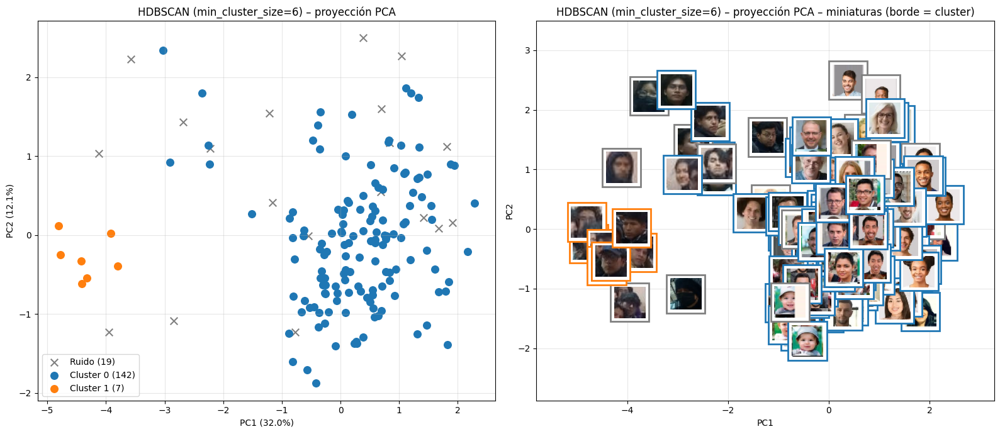

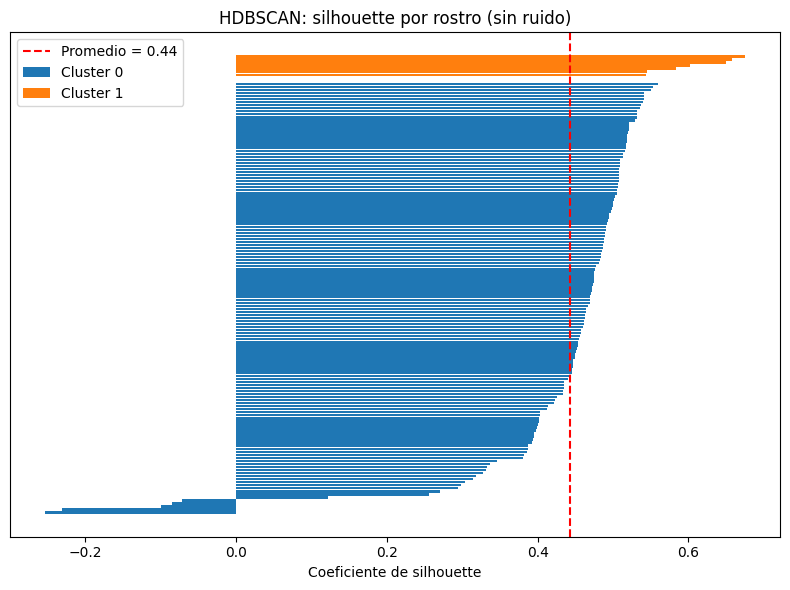

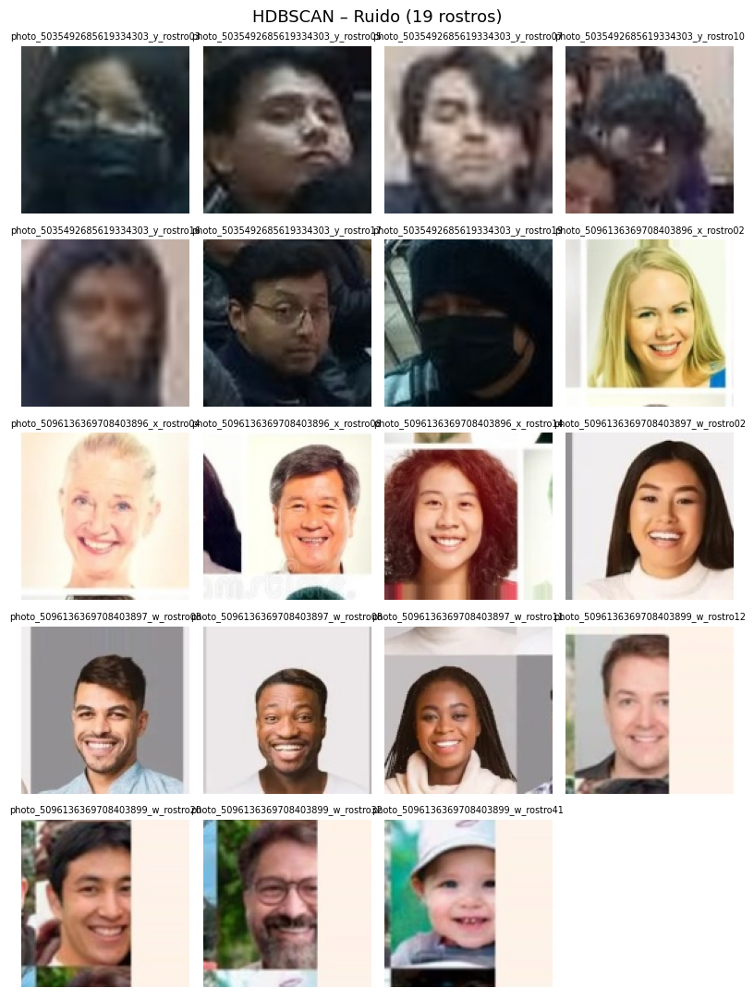

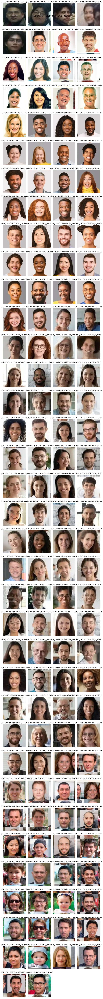

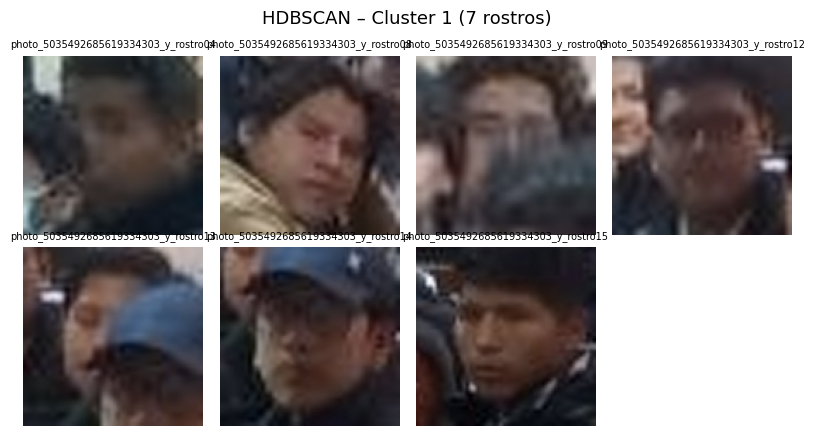

In [20]:
hdb = HDBSCAN(min_cluster_size=mcs_hdb, min_samples=MIN_SAMPLES_HDB).fit(Xw)
etiquetas_hdb = hdb.labels_
df["cluster_hdbscan"] = etiquetas_hdb
n_cl_hdb = len(set(etiquetas_hdb[etiquetas_hdb != -1]))
print(f"HDBSCAN encontró {n_cl_hdb} clusters y {(etiquetas_hdb == -1).sum()} rostros de ruido ({(etiquetas_hdb == -1).mean():.1%}).")
print(pd.Series(etiquetas_hdb).value_counts().sort_index().rename("rostros por cluster (-1 = ruido)"))

# Probabilidad de pertenencia de cada rostro a su cluster
probs_hdb = getattr(hdb, "probabilities_", None)
if probs_hdb is not None:
    df["prob_hdbscan"] = probs_hdb
    plt.figure(figsize=(7, 3.8))
    plt.hist(probs_hdb[etiquetas_hdb != -1], bins=20, color="tab:purple", alpha=.8)
    plt.title("HDBSCAN: probabilidad de pertenencia (rostros que sí tienen cluster)")
    plt.xlabel("Probabilidad (1 = núcleo del cluster, ~0 = borde)"); plt.ylabel("Nº de rostros"); plt.grid(alpha=.3)
    plt.tight_layout(); guardar("24_hdbscan_probabilidades.png"); plt.show()

graficar_pca(etiquetas_hdb, f"HDBSCAN (min_cluster_size={mcs_hdb}) – proyección PCA", "25_hdbscan_pca.png")
graficar_silhouette(etiquetas_hdb, "HDBSCAN: silhouette por rostro (sin ruido)", "26_hdbscan_silhouette.png")
grid_clusters(etiquetas_hdb, "HDBSCAN", "27_hdbscan_cluster")

## 14) OPTICS: gráfica de alcanzabilidad, barrido de `xi`, métricas y clusters
OPTICS es el "hermano mayor" de DBSCAN: en vez de fijar un único `eps`, **ordena los rostros** y calcula para cada uno una *distancia de alcanzabilidad*.
Con eso se obtiene la **gráfica de alcanzabilidad** (reachability plot): los **valles** son clusters densos y los **picos** son las fronteras o el ruido.

- **Codo de OPTICS = gráfica de alcanzabilidad**: cuenta los valles profundos y separados por picos altos.
- `min_samples`: vecinos mínimos para ser punto núcleo (igual que en DBSCAN).
- `xi`: cuán pronunciada debe ser la subida/bajada en la alcanzabilidad para separar clusters (pequeño = más clusters, grande = menos). Se barre y se elige igual que `eps` en DBSCAN.
- Las métricas internas se calculan **sin contar el ruido (-1)**, por eso también se reporta el % de ruido.

xi usado: 0.036  (mejor silhouette con ruido <= 40%) | min_samples = 5


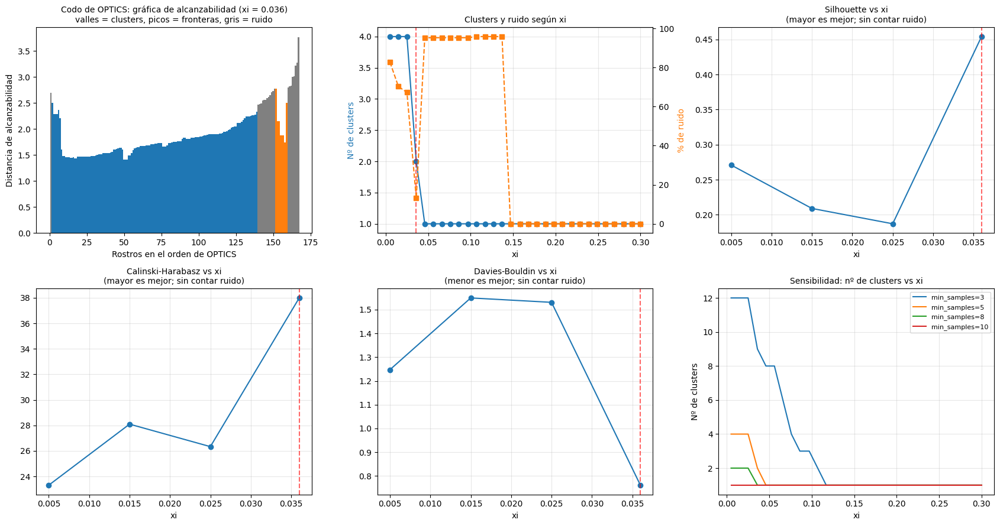

,xi,n_clusters,ruido,silhouette,calinski,davies_bouldin
0,0.005,4,0.827,0.271,23.317,1.247
1,0.015,4,0.702,0.209,28.099,1.549
2,0.025,4,0.673,0.187,26.336,1.530
3,0.036,2,0.131,0.454,37.990,0.762
4,0.046,1,0.952,NaN,NaN,NaN
5,0.056,1,0.952,NaN,NaN,NaN
6,0.066,1,0.952,NaN,NaN,NaN
7,0.076,1,0.952,NaN,NaN,NaN
8,0.086,1,0.952,NaN,NaN,NaN
9,0.097,1,0.952,NaN,NaN,NaN


In [21]:
# ---------------- Parámetros nuevos (OPTICS) ----------------
from sklearn.cluster import OPTICS, cluster_optics_xi

MIN_SAMPLES_OPT = 5      # OPTICS: vecinos mínimos (prueba 3-10)
MIN_CLUSTER_OPT = None   # OPTICS: tamaño mínimo de cluster. None = igual a min_samples
XI_ELEGIDO      = None   # OPTICS: None = automático (mejor silhouette con ruido <= MAX_RUIDO). O pon un valor, ej. 0.05

# ---------- Ordenamiento OPTICS (se calcula una sola vez) ----------
opt_base = OPTICS(min_samples=MIN_SAMPLES_OPT, min_cluster_size=MIN_CLUSTER_OPT, xi=0.05).fit(Xw)

# ---------- Barrido de xi (se reextraen los clusters sin recalcular el orden) ----------
xi_grid = np.round(np.linspace(0.005, 0.30, 30), 3)
filas = []
for xi_ in xi_grid:
    lab, _ = cluster_optics_xi(reachability=opt_base.reachability_, predecessor=opt_base.predecessor_,
                               ordering=opt_base.ordering_, min_samples=MIN_SAMPLES_OPT,
                               min_cluster_size=MIN_CLUSTER_OPT, xi=float(xi_))
    mk = lab != -1
    fila = dict(xi=xi_, n_clusters=len(set(lab[mk])), ruido=1 - mk.mean())
    fila.update(metricas_internas(Xw, lab))
    filas.append(fila)
df_xi = pd.DataFrame(filas)

# ---------- Elección de xi ----------
validos = df_xi[(df_xi.n_clusters >= 2) & (df_xi.ruido <= MAX_RUIDO)].dropna(subset=["silhouette"])
if XI_ELEGIDO is not None:
    xi_opt, origen = float(XI_ELEGIDO), "manual"
elif len(validos):
    xi_opt, origen = float(validos.loc[validos.silhouette.idxmax(), "xi"]), f"mejor silhouette con ruido <= {MAX_RUIDO:.0%}"
else:
    xi_opt, origen = 0.05, "valor por defecto (ningún xi dio >= 2 clusters con poco ruido)"
print(f"xi usado: {xi_opt}  ({origen}) | min_samples = {MIN_SAMPLES_OPT}")

# ---------- Gráficas ----------
lab_vis, _ = cluster_optics_xi(reachability=opt_base.reachability_, predecessor=opt_base.predecessor_,
                               ordering=opt_base.ordering_, min_samples=MIN_SAMPLES_OPT,
                               min_cluster_size=MIN_CLUSTER_OPT, xi=xi_opt)
orden_o = opt_base.ordering_
reach = opt_base.reachability_[orden_o].copy()
reach[~np.isfinite(reach)] = np.nan                       # el primer punto tiene alcanzabilidad infinita

fig, axs = plt.subplots(2, 3, figsize=(17, 9))
ax = axs[0, 0]
ax.bar(range(len(reach)), np.nan_to_num(reach), width=1.0, color=[color_cluster(k) for k in lab_vis[orden_o]])
ax.set_title(f"Codo de OPTICS: gráfica de alcanzabilidad (xi = {xi_opt})\nvalles = clusters, picos = fronteras, gris = ruido", fontsize=10)
ax.set_xlabel("Rostros en el orden de OPTICS"); ax.set_ylabel("Distancia de alcanzabilidad")

axs[0, 1].plot(df_xi.xi, df_xi.n_clusters, "o-", color="tab:blue")
axs[0, 1].set_ylabel("Nº de clusters", color="tab:blue")
ax2 = axs[0, 1].twinx(); ax2.plot(df_xi.xi, df_xi.ruido * 100, "s--", color="tab:orange")
ax2.set_ylabel("% de ruido", color="tab:orange")
axs[0, 1].set_title("Clusters y ruido según xi", fontsize=10)

for ax, col, titulo, nota in [(axs[0, 2], "silhouette", "Silhouette vs xi", "mayor es mejor"),
                              (axs[1, 0], "calinski", "Calinski-Harabasz vs xi", "mayor es mejor"),
                              (axs[1, 1], "davies_bouldin", "Davies-Bouldin vs xi", "menor es mejor")]:
    ax.plot(df_xi.xi, df_xi[col], "o-")
    ax.set_title(f"{titulo}\n({nota}; sin contar ruido)", fontsize=10)
for ax in (axs[0, 1], axs[0, 2], axs[1, 0], axs[1, 1]):
    ax.axvline(xi_opt, color="red", ls="--", alpha=.6); ax.set_xlabel("xi"); ax.grid(alpha=.3)

# sensibilidad a min_samples
for ms in (3, 5, 8, 10):
    o_ = OPTICS(min_samples=ms, min_cluster_size=MIN_CLUSTER_OPT, xi=0.05).fit(Xw)
    ncl = []
    for xi_ in xi_grid:
        lab, _ = cluster_optics_xi(reachability=o_.reachability_, predecessor=o_.predecessor_,
                                   ordering=o_.ordering_, min_samples=ms,
                                   min_cluster_size=MIN_CLUSTER_OPT, xi=float(xi_))
        ncl.append(len(set(lab[lab != -1])))
    axs[1, 2].plot(xi_grid, ncl, label=f"min_samples={ms}")
axs[1, 2].set_title("Sensibilidad: nº de clusters vs xi", fontsize=10)
axs[1, 2].set_xlabel("xi"); axs[1, 2].set_ylabel("Nº de clusters"); axs[1, 2].legend(fontsize=8); axs[1, 2].grid(alpha=.3)
plt.tight_layout(); guardar("28_optics_metricas_xi.png"); plt.show()

display(df_xi.round(3))

OPTICS encontró 2 clusters y 22 rostros de ruido (13.1%).
-1     22
 0    138
 1      8
Name: rostros por cluster (-1 = ruido), dtype: int64


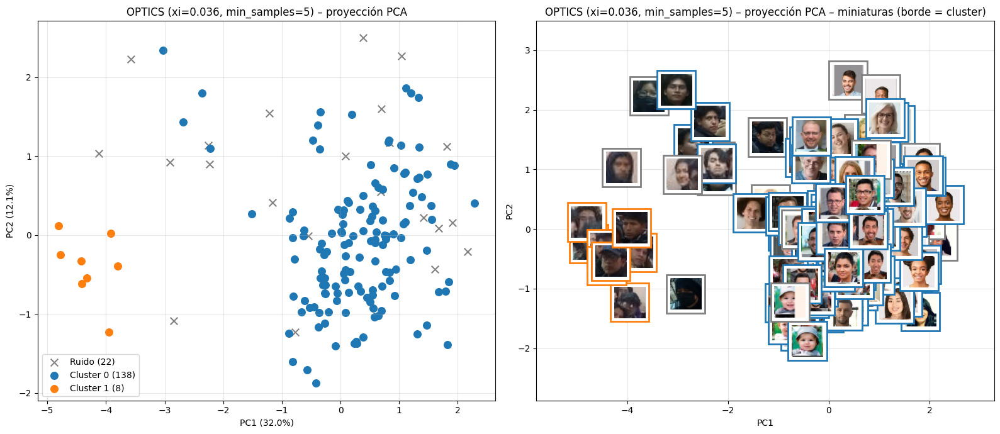

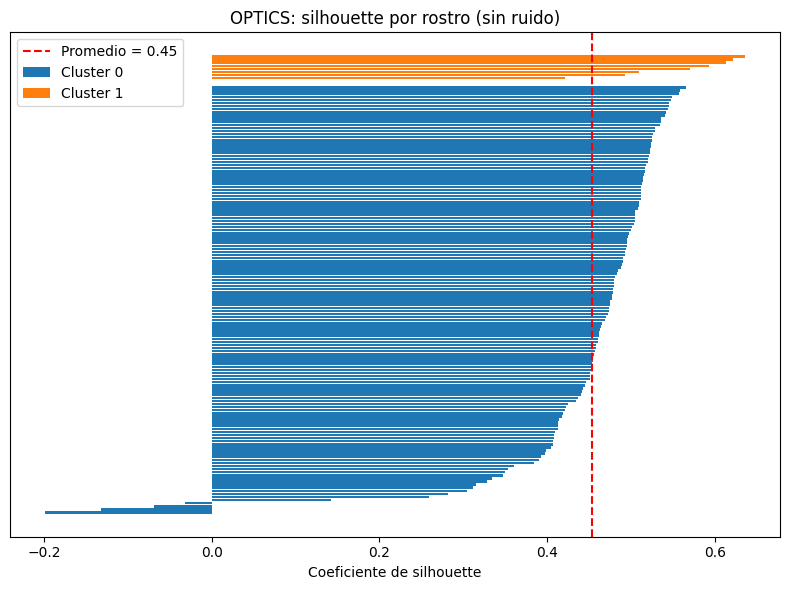

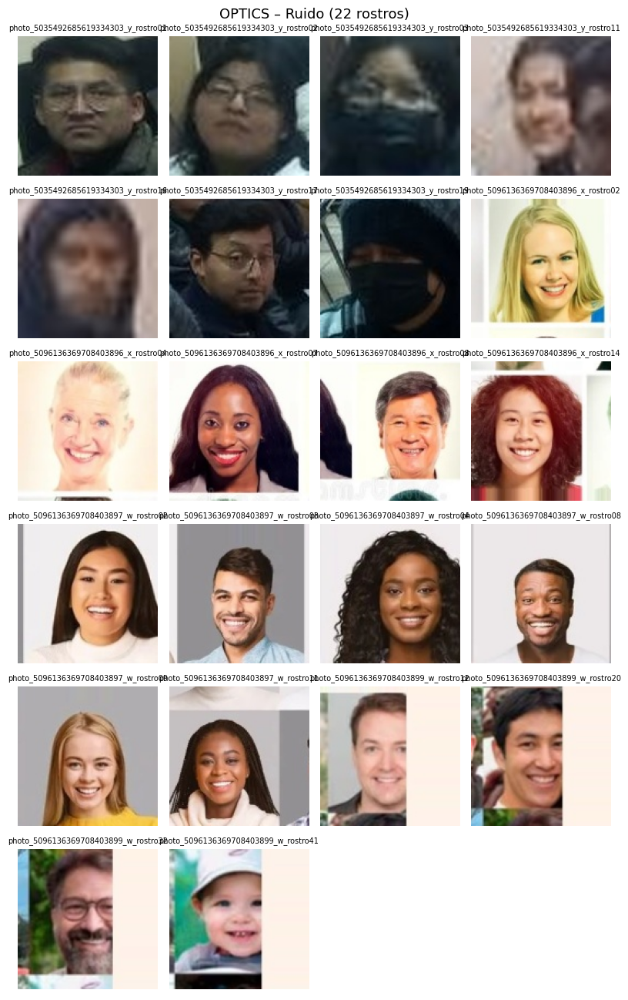

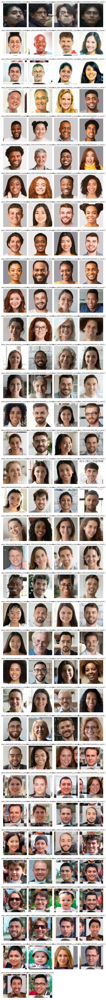

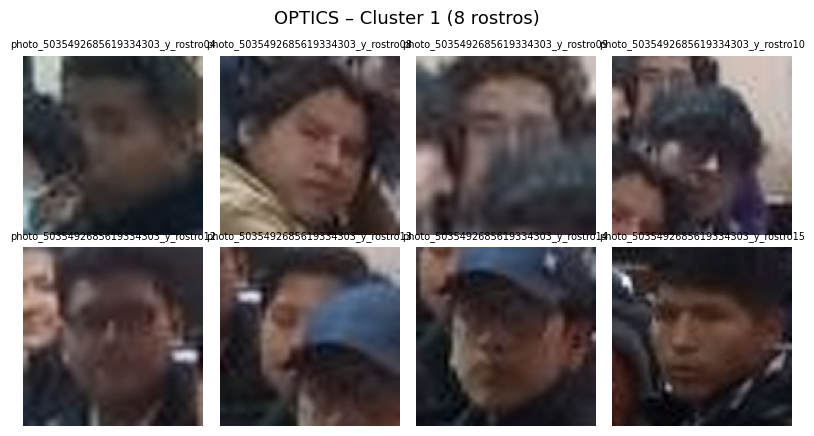

In [22]:
optics = OPTICS(min_samples=MIN_SAMPLES_OPT, min_cluster_size=MIN_CLUSTER_OPT, xi=xi_opt).fit(Xw)
etiquetas_opt = optics.labels_
df["cluster_optics"] = etiquetas_opt
n_cl_opt = len(set(etiquetas_opt[etiquetas_opt != -1]))
print(f"OPTICS encontró {n_cl_opt} clusters y {(etiquetas_opt == -1).sum()} rostros de ruido ({(etiquetas_opt == -1).mean():.1%}).")
print(pd.Series(etiquetas_opt).value_counts().sort_index().rename("rostros por cluster (-1 = ruido)"))

graficar_pca(etiquetas_opt, f"OPTICS (xi={xi_opt}, min_samples={MIN_SAMPLES_OPT}) – proyección PCA", "29_optics_pca.png")
graficar_silhouette(etiquetas_opt, "OPTICS: silhouette por rostro (sin ruido)", "30_optics_silhouette.png")
grid_clusters(etiquetas_opt, "OPTICS", "31_optics_cluster")

## 15) Comparación: Jerárquico vs K-Means vs DBSCAN vs HDBSCAN vs OPTICS
Se comparan con **los mismos datos** (`Xw`) y, para jerárquico y K-Means, **el mismo k**. Criterios:

| Criterio | Qué responde |
|---|---|
| **Silhouette, Calinski-Harabasz, Davies-Bouldin** | ¿Qué tan compactos y separados quedan los grupos? (internas, no necesitan etiquetas reales) |
| **Estabilidad (ARI en remuestreos)** | Si quito 20 % de los rostros y repito, ¿obtengo los mismos grupos? (1 = idéntico, 0 = azar) |
| **Cobertura** | % de rostros que el algoritmo realmente agrupa (DBSCAN, HDBSCAN y OPTICS dejan ruido sin grupo) |
| **Balance** | % del cluster más grande; si es ~100 % el algoritmo casi no separa nada |
| **ARI / NMI entre algoritmos** | ¿Los algoritmos están de acuerdo en qué rostros van juntos? |

> Las métricas internas **no usan etiquetas reales** (no sabemos quién es quién), así que ayudan a comparar pero no son una verdad absoluta; por eso se combinan con la inspección visual de los rostros de cada cluster.
> En los algoritmos de densidad (DBSCAN, HDBSCAN, OPTICS) las métricas se calculan sin el ruido, así que un algoritmo que descarta muchos rostros puede verse "mejor" de lo que es: mira siempre **cobertura** y **% de ruido** junto a las métricas.

In [23]:
def estabilidad(ajustar, X, lab_full, n=N_BOOT, frac=0.8, seed=0):
    """ARI medio entre las etiquetas del modelo completo y las de modelos ajustados con submuestras."""
    rng = np.random.default_rng(seed)
    aris = []
    for _ in range(n):
        idx = rng.choice(len(X), int(frac * len(X)), replace=False)
        aris.append(adjusted_rand_score(lab_full[idx], ajustar(X[idx])))
    return float(np.mean(aris)), float(np.std(aris))

ajustadores = {
    "Jerárquico (Ward)": lambda X: AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(X),
    "K-Means":           lambda X: KMeans(n_clusters=K_KM, n_init=10, random_state=0).fit_predict(X),
    "DBSCAN":            lambda X: DBSCAN(eps=eps_db, min_samples=MIN_SAMPLES).fit_predict(X),
    "HDBSCAN":           lambda X: HDBSCAN(min_cluster_size=mcs_hdb, min_samples=MIN_SAMPLES_HDB).fit_predict(X),
    "OPTICS":            lambda X: OPTICS(min_samples=MIN_SAMPLES_OPT, min_cluster_size=MIN_CLUSTER_OPT, xi=xi_opt).fit_predict(X),
}
resultados = {"Jerárquico (Ward)": etiquetas_jer, "K-Means": etiquetas_km, "DBSCAN": etiquetas_db,
              "HDBSCAN": etiquetas_hdb, "OPTICS": etiquetas_opt}

filas = {}
for nombre, lab in resultados.items():
    met = metricas_internas(Xw, lab)
    est_m, est_s = estabilidad(ajustadores[nombre], Xw, lab)
    tam = pd.Series(lab[lab != -1]).value_counts()
    filas[nombre] = {
        "n_clusters": len(set(lab[lab != -1])),
        "ruido_%": 100 * (lab == -1).mean(),
        "cobertura": (lab != -1).mean(),
        "cluster_mayor_%": 100 * tam.max() / len(lab) if len(tam) else np.nan,
        **met,
        "estabilidad_ARI": est_m,
        "estabilidad_std": est_s,
    }
df_comp = pd.DataFrame(filas).T
print("Tabla comparativa (métricas internas de DBSCAN calculadas sin el ruido):")
display(df_comp.round(3))
df_comp.to_csv(os.path.join(RESULTADOS, "comparacion_algoritmos.csv"))

Tabla comparativa (métricas internas de DBSCAN calculadas sin el ruido):


,n_clusters,ruido_%,cobertura,cluster_mayor_%,silhouette,calinski,davies_bouldin,estabilidad_ARI,estabilidad_std
Jerárquico (Ward),3.0,0.000,1.000,63.095,0.174,37.621,2.014,0.732,0.085
K-Means,3.0,0.000,1.000,55.952,0.172,40.475,1.940,0.943,0.083
DBSCAN,2.0,39.881,0.601,57.143,0.518,33.145,0.618,0.834,0.098
HDBSCAN,2.0,11.310,0.887,84.524,0.444,33.202,0.720,0.359,0.401
OPTICS,2.0,13.095,0.869,82.143,0.454,37.990,0.762,0.364,0.297


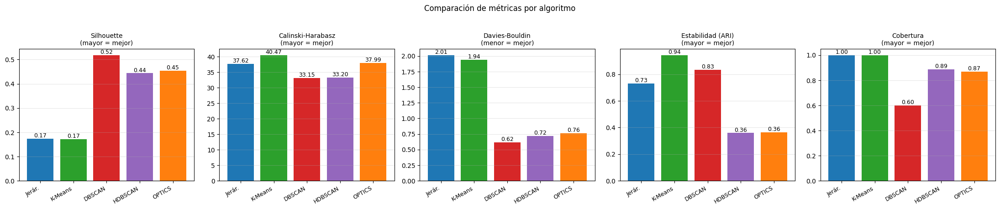

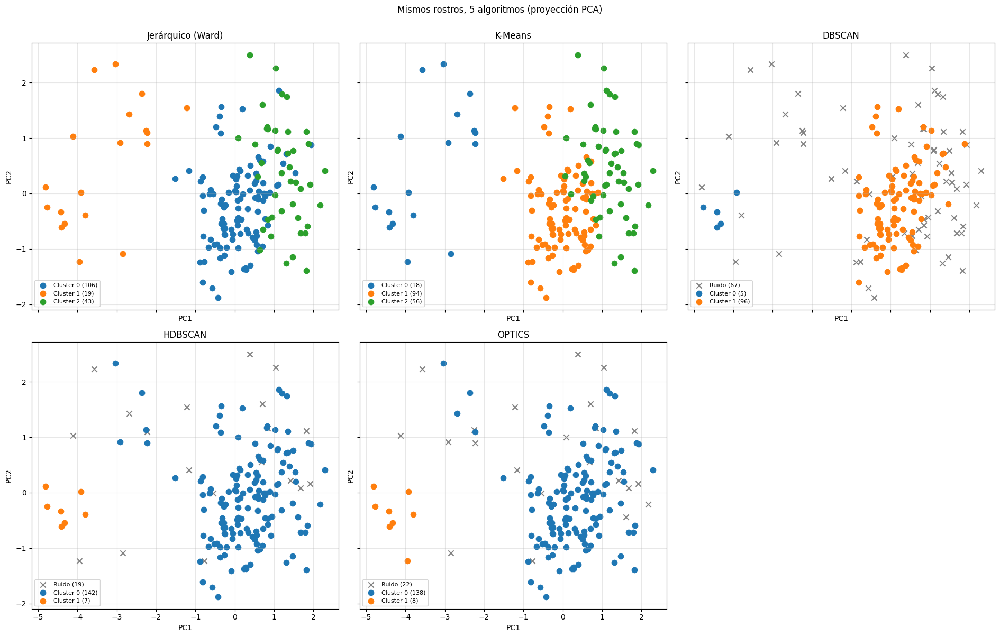

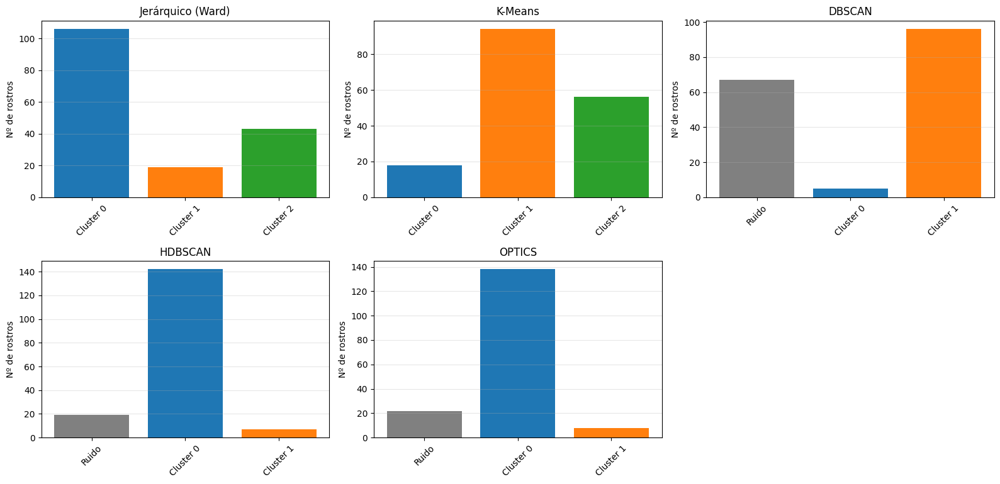

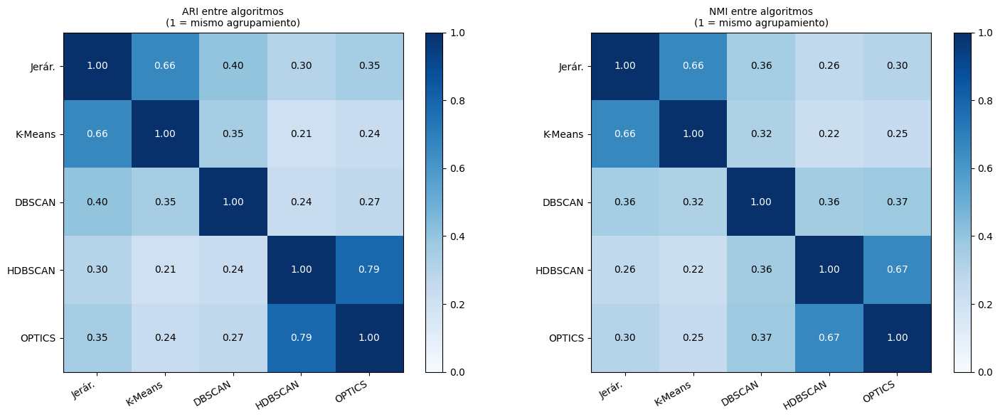

In [24]:
nombres_alg = list(resultados)
n_alg = len(nombres_alg)
col_alg = {"Jerárquico (Ward)": "tab:blue", "K-Means": "tab:green", "DBSCAN": "tab:red",
           "HDBSCAN": "tab:purple", "OPTICS": "tab:orange"}
corto   = {"Jerárquico (Ward)": "Jerár.", "K-Means": "K-Means", "DBSCAN": "DBSCAN",
           "HDBSCAN": "HDBSCAN", "OPTICS": "OPTICS"}
etq_cortas = [corto[n] for n in nombres_alg]

# ---- (a) Barras de métricas ----
fig, axs = plt.subplots(1, 5, figsize=(22, 4.4))
barras = [("silhouette", "Silhouette\n(mayor = mejor)"), ("calinski", "Calinski-Harabasz\n(mayor = mejor)"),
          ("davies_bouldin", "Davies-Bouldin\n(menor = mejor)"), ("estabilidad_ARI", "Estabilidad (ARI)\n(mayor = mejor)"),
          ("cobertura", "Cobertura\n(mayor = mejor)")]
for ax, (col, titulo) in zip(axs, barras):
    vals = df_comp[col].astype(float).values
    ax.bar(range(n_alg), np.nan_to_num(vals), color=[col_alg[n] for n in nombres_alg])
    for i, v in enumerate(vals):
        ax.text(i, 0 if np.isnan(v) else v, "n/a" if np.isnan(v) else f"{v:.2f}", ha="center", va="bottom", fontsize=9)
    ax.set_xticks(range(n_alg)); ax.set_xticklabels(etq_cortas, rotation=30, ha="right", fontsize=9)
    ax.set_title(titulo, fontsize=10); ax.grid(alpha=.3, axis="y")
plt.suptitle("Comparación de métricas por algoritmo", y=1.03)
plt.tight_layout(); guardar("19_comparacion_metricas.png"); plt.show()

# ---- (b) Los clusterings sobre el mismo PCA ----
ncols_g = 3
nrows_g = (n_alg + ncols_g - 1) // ncols_g
fig, axs = plt.subplots(nrows_g, ncols_g, figsize=(19, 6 * nrows_g), sharex=True, sharey=True, squeeze=False)
for ax in axs.flatten():
    ax.axis("off")
for ax, nombre in zip(axs.flatten(), nombres_alg):
    ax.axis("on")
    lab = resultados[nombre]
    for k in sorted(set(lab)):
        m = lab == k
        ax.scatter(X2[m, 0], X2[m, 1], s=55, color=color_cluster(k), marker="x" if k == -1 else "o",
                   label=f"{nombre_cluster(k)} ({m.sum()})")
    ax.set_title(nombre); ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.suptitle(f"Mismos rostros, {n_alg} algoritmos (proyección PCA)", y=1.0)
plt.tight_layout(); guardar("20_comparacion_pca.png"); plt.show()

# ---- (c) Tamaño de los clusters ----
fig, axs = plt.subplots(nrows_g, ncols_g, figsize=(16, 3.9 * nrows_g), squeeze=False)
for ax in axs.flatten():
    ax.axis("off")
for ax, nombre in zip(axs.flatten(), nombres_alg):
    ax.axis("on")
    vc = pd.Series(resultados[nombre]).value_counts().sort_index()
    ax.bar([nombre_cluster(k) for k in vc.index], vc.values, color=[color_cluster(k) for k in vc.index])
    ax.set_title(nombre); ax.tick_params(axis="x", rotation=45); ax.grid(alpha=.3, axis="y")
    ax.set_ylabel("Nº de rostros")
plt.tight_layout(); guardar("21_comparacion_tamanos.png"); plt.show()

# ---- (d) Acuerdo entre algoritmos (ARI y NMI; el ruido cuenta como una etiqueta más) ----
ari = pd.DataFrame(index=nombres_alg, columns=nombres_alg, dtype=float)
nmi = ari.copy()
for a in nombres_alg:
    for b in nombres_alg:
        ari.loc[a, b] = adjusted_rand_score(resultados[a], resultados[b])
        nmi.loc[a, b] = normalized_mutual_info_score(resultados[a], resultados[b])
fig, axs = plt.subplots(1, 2, figsize=(15, 6))
for ax, mat, t in zip(axs, (ari, nmi), ("ARI entre algoritmos", "NMI entre algoritmos")):
    im_ = ax.imshow(mat.values, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(n_alg)); ax.set_xticklabels(etq_cortas, rotation=30, ha="right")
    ax.set_yticks(range(n_alg)); ax.set_yticklabels(etq_cortas)
    for i in range(n_alg):
        for j in range(n_alg):
            ax.text(j, i, f"{mat.values[i, j]:.2f}", ha="center", va="center",
                    color="white" if mat.values[i, j] > .6 else "black")
    ax.set_title(t + "\n(1 = mismo agrupamiento)", fontsize=10); plt.colorbar(im_, ax=ax, fraction=.046)
plt.tight_layout(); guardar("22_acuerdo_algoritmos.png"); plt.show()


Puesto por criterio (1 = mejor):


,silhouette,calinski,davies_bouldin,estabilidad_ARI,cobertura,puesto_promedio
K-Means,5.0,1.0,4.0,1.0,1.0,2.4
DBSCAN,1.0,5.0,1.0,2.0,5.0,2.8
OPTICS,2.0,2.0,3.0,4.0,4.0,3.0
Jerárquico (Ward),4.0,3.0,5.0,3.0,1.0,3.2
HDBSCAN,3.0,4.0,2.0,5.0,3.0,3.4


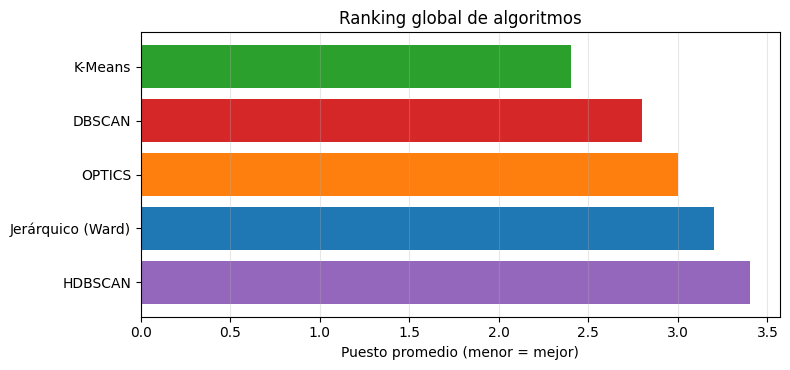


>>> Mejor algoritmo según el puesto promedio: K-Means
⚠ HDBSCAN metió >80 % de los rostros en un solo cluster: casi no está separando.
⚠ OPTICS metió >80 % de los rostros en un solo cluster: casi no está separando.

Revisa también visualmente las cuadrículas de rostros de cada cluster (archivos 06_, 14_, 18_, 27_ y 31_ en resultados/):
una métrica alta no garantiza que los grupos tengan sentido para ti.


In [25]:
# ---------------- Ranking y criterio automático ----------------
# Se ordena a los algoritmos en cada criterio (1 = mejor) y se promedian los puestos.
criterios = {"silhouette": True, "calinski": True, "davies_bouldin": False,
             "estabilidad_ARI": True, "cobertura": True}          # True = mayor es mejor
ranking = pd.DataFrame({c: df_comp[c].astype(float).rank(ascending=not mayor, method="min", na_option="bottom")
                        for c, mayor in criterios.items()})
ranking["puesto_promedio"] = ranking.mean(axis=1)
ranking = ranking.sort_values("puesto_promedio")
print("Puesto por criterio (1 = mejor):")
display(ranking.round(2))

# Gráfico del ranking
plt.figure(figsize=(8, 3.8))
plt.barh(ranking.index[::-1], ranking["puesto_promedio"][::-1], color=[col_alg[n] for n in ranking.index[::-1]])
plt.xlabel("Puesto promedio (menor = mejor)"); plt.title("Ranking global de algoritmos"); plt.grid(alpha=.3, axis="x")
plt.tight_layout(); guardar("23b_ranking_algoritmos.png"); plt.show()

mejor = ranking.index[0]
print(f"\n>>> Mejor algoritmo según el puesto promedio: {mejor}")
for alg in ("DBSCAN", "HDBSCAN", "OPTICS"):
    if df_comp.loc[alg, "ruido_%"] > 100 * MAX_RUIDO:
        print(f"⚠ {alg} dejó {df_comp.loc[alg, 'ruido_%']:.0f} % de los rostros como ruido: sus métricas internas son poco comparables.")
    if df_comp.loc[alg, "cluster_mayor_%"] > 80:
        print(f"⚠ {alg} metió >80 % de los rostros en un solo cluster: casi no está separando.")
if df_comp.loc[nombres_alg, "n_clusters"].min() < 2:
    print("⚠ Algún algoritmo produjo menos de 2 clusters; revisa sus parámetros (eps / min_cluster_size / xi).")
print("\nRevisa también visualmente las cuadrículas de rostros de cada cluster (archivos 06_, 14_, 18_, 27_ y 31_ en resultados/):")
print("una métrica alta no garantiza que los grupos tengan sentido para ti.")


### Cómo interpretar la comparación (criterio para elegir el modelo con rostros)

**Qué esperar de cada algoritmo con este tipo de datos** (rostros descritos por color, luz, textura, HOG, lentes y simetría):

| | Jerárquico (Ward) | K-Means | DBSCAN | HDBSCAN | OPTICS |
|---|---|---|---|---|---|
| **Necesita k** | Sí (el dendrograma ayuda) | Sí (codo, Silhouette, Calinski) | No | No | No |
| **Parámetros clave** | `k`, linkage | `k` | `eps` y `min_samples` (difícil de afinar) | `min_cluster_size` (intuitivo) | `min_samples` y `xi` |
| **Forma de los grupos** | Compactos | Compactos y de tamaño parecido | Cualquier forma, **una sola densidad** | Cualquier forma, **densidades distintas** | Cualquier forma, densidades distintas |
| **Ruido / atípicos** | Los obliga a entrar en un cluster | Los obliga a entrar (y mueven centroides) | Los marca como ruido (-1) | Los marca como ruido (-1) y da probabilidad de pertenencia | Los marca como ruido (-1) |
| **Determinista** | Sí | Depende de la inicialización (`n_init=10`) | Sí | Sí | Sí |
| **Alta dimensión (170 variables)** | Ward se comporta bien | Bien | El más afectado: las distancias se parecen | Más robusto que DBSCAN, pero también sufre | Sufre igual que DBSCAN; la gráfica de alcanzabilidad ayuda a diagnosticar |
| **Interpretación** | Dendrograma | Centroides ("rostro promedio") | Descubre rostros "raros" | Clusters estables + probabilidad por rostro | Gráfica de alcanzabilidad (valles = grupos) |

**Cómo decidir:**
1. Si los grupos tienen **buena Silhouette/Calinski, baja Davies-Bouldin y alta estabilidad**, y además las cuadrículas de rostros se ven coherentes → ese es el modelo.
2. Si **jerárquico y K-Means coinciden** (ARI alto), la estructura es robusta y da igual cuál uses; elige el más fácil de explicar (K-Means con centroides, o jerárquico con dendrograma).
3. Si **DBSCAN, HDBSCAN u OPTICS dejan mucho ruido** o meten casi todo en un cluster, no son adecuados para estas características como repartidores de grupos; su mejor uso aquí es **detectar atípicos** (falsos positivos del detector, fotos muy borrosas, perfiles). Sus métricas se calculan sin el ruido, así que compáralas siempre junto con la **cobertura**.
4. Si **HDBSCAN u OPTICS** encuentran grupos distintos a los de DBSCAN con la misma cobertura, es señal de que los grupos tienen **densidades diferentes** (DBSCAN no puede capturarlo con un único `eps`).
5. Recuerda que **no hay etiquetas reales** (no sabemos quién es quién): las métricas son internas y el resultado depende de las características y pesos (`PESOS`) que elegiste. Si quisieras agrupar *por identidad* (misma persona), tendrías que usar *embeddings* faciales (p. ej. FaceNet/ArcFace) en lugar de color/HOG/LBP.

## 16) Exportar resultados

In [26]:
cols_clusters = ["cluster", "cluster_kmeans", "cluster_dbscan", "cluster_hdbscan", "cluster_optics"]
todos = df[cols_clusters + ["indice_lentes"]].copy()
todos = todos.rename(columns={"cluster": "cluster_jerarquico"})
if "prob_hdbscan" in df.columns:
    todos["prob_hdbscan"] = df["prob_hdbscan"]
todos.insert(0, "rostro", df.index)
todos.to_csv(os.path.join(RESULTADOS, "clusters_todos_los_algoritmos.csv"), index=False)
print("Guardado en:", os.path.join(RESULTADOS, "clusters_todos_los_algoritmos.csv"))
print("Tabla comparativa en:", os.path.join(RESULTADOS, "comparacion_algoritmos.csv"))
todos.head(15)

Guardado en: /content/drive/MyDrive/ANALISIS_ROSTROS/resultados/clusters_todos_los_algoritmos.csv
Tabla comparativa en: /content/drive/MyDrive/ANALISIS_ROSTROS/resultados/comparacion_algoritmos.csv


,rostro,cluster_jerarquico,cluster_kmeans,cluster_dbscan,cluster_hdbscan,cluster_optics,indice_lentes,prob_hdbscan
photo_5035492685619334303_y_rostro01.jpg,photo_5035492685619334303_y_rostro01.jpg,1,0,-1,0,-1,-0.428795,0.567229
photo_5035492685619334303_y_rostro02.jpg,photo_5035492685619334303_y_rostro02.jpg,1,0,-1,0,-1,-0.257639,0.596751
photo_5035492685619334303_y_rostro03.jpg,photo_5035492685619334303_y_rostro03.jpg,1,0,-1,-1,-1,-0.315502,0.000000
photo_5035492685619334303_y_rostro04.jpg,photo_5035492685619334303_y_rostro04.jpg,1,0,0,1,1,-2.104469,1.000000
photo_5035492685619334303_y_rostro05.jpg,photo_5035492685619334303_y_rostro05.jpg,1,0,-1,-1,0,-0.276502,0.000000
photo_5035492685619334303_y_rostro06.jpg,photo_5035492685619334303_y_rostro06.jpg,1,0,-1,0,0,0.048303,0.646542
photo_5035492685619334303_y_rostro07.jpg,photo_5035492685619334303_y_rostro07.jpg,1,0,-1,-1,0,-0.207213,0.000000
photo_5035492685619334303_y_rostro08.jpg,photo_5035492685619334303_y_rostro08.jpg,1,0,-1,1,1,-1.674812,1.000000
photo_5035492685619334303_y_rostro09.jpg,photo_5035492685619334303_y_rostro09.jpg,1,0,-1,1,1,-1.805847,0.951231
photo_5035492685619334303_y_rostro10.jpg,photo_5035492685619334303_y_rostro10.jpg,1,0,-1,-1,1,-1.691882,0.000000
